# 邏輯回歸

- **核心原理**：Sigmoid、交叉熵
- **變體**：Softmax 多分類
- **推薦資料集**：Breast Cancer Wisconsin（569 筆、30 個特徵；**0 = 惡性 malignant、1 = 良性 benign**）

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

---
## 1. 資料與探索性資料分析（EDA）

觀察直接寫在每格程式最上面的註解（跟前兩章一樣）。

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ml_dl_llm.data import load_breast_cancer

X_train, X_test, y_train, y_test = load_breast_cancer()
train = X_train.assign(label=y_train)

print("train / test：", X_train.shape, X_test.shape)
print("標籤：0 = malignant（惡性）、1 = benign（良性）")

train / test： (455, 30) (114, 30)
標籤：0 = malignant（惡性）、1 = benign（良性）


In [2]:
# 觀察：455 筆、30 個特徵，全部是 float64 的連續型變數，沒有缺值 → 不需要補值或類別編碼。
#   30 個特徵 = 10 種細胞核測量 × 3 種統計量：
#     測量：radius、texture、perimeter、area、smoothness、compactness、concavity、concave points、symmetry、fractal dimension
#     統計量：mean（平均）、error（標準誤）、worst（最大 3 個值的平均）
#   這個「同一測量出現 3 次」的結構，是後面共線性的主要來源之一。
X_train.info()

<class 'pandas.DataFrame'>
Index: 455 entries, 546 to 474
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              455 non-null    float64
 1   mean texture             455 non-null    float64
 2   mean perimeter           455 non-null    float64
 3   mean area                455 non-null    float64
 4   mean smoothness          455 non-null    float64
 5   mean compactness         455 non-null    float64
 6   mean concavity           455 non-null    float64
 7   mean concave points      455 non-null    float64
 8   mean symmetry            455 non-null    float64
 9   mean fractal dimension   455 non-null    float64
 10  radius error             455 non-null    float64
 11  texture error            455 non-null    float64
 12  perimeter error          455 non-null    float64
 13  area error               455 non-null    float64
 14  smoothness error         455 non-null   

In [3]:
# 觀察：良性 285 筆（62.6%）、惡性 170 筆（37.4%），約 1.7 : 1，屬於輕度不平衡。
#   load_breast_cancer 已依標籤分層切分（stratify），train 與 test 的類別比例一致。
#   - 「永遠猜良性」的 accuracy = 0.626，這才是 accuracy 的實際起點（不是 0.5）。
#   - 這個比例不需要重抽樣；真正的問題是兩種錯誤的代價不對稱（惡性判成良性遠比反過來嚴重），
#     因此除了 accuracy 還要看惡性的 recall，必要時調整分類門檻（第 5 節）。
display(y_train.value_counts().to_frame("count").assign(ratio=y_train.value_counts(normalize=True).round(3)))

,count,ratio
target,,
1,285,0.626
0,170,0.374


In [4]:
# 觀察：特徵尺度差異極大。平均值從 0.0038（fractal dimension error）到 869（worst area），相差約 2×10⁵ 倍；
#   標準差的差距也約 2×10⁵ 倍（worst area vs fractal dimension error）。
#   差異主要來自「量的種類」不同，而不只是單位：
#     area 是長度²（~10²–10³）、radius／perimeter 是長度（~10¹–10²），
#     smoothness、compactness、symmetry、fractal dimension 是無因次比值（~10⁻³–10⁻¹）。
#   area 類右偏、長尾明顯：worst area 中位數 683、75% 分位數 1034、最大值 3432；error 類偏態最大（skew 3–5）。
#   concavity、concave points 相關的 6 個特徵各有 11 筆為 0（輪廓沒有凹陷），是合理值而非缺值。
#   → 梯度下降與 L2 正則化之前都必須標準化（理由見 TODO 1 (2)）。
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,455.0,14.067213,3.499380,6.981000,11.635000,13.270000,15.740000,28.11000
mean texture,455.0,19.247363,4.405291,9.710000,16.000000,18.820000,21.710000,39.28000
mean perimeter,455.0,91.557407,24.149231,43.790000,74.720000,85.980000,103.700000,188.50000
mean area,455.0,648.541099,344.944564,143.500000,415.650000,541.800000,770.050000,2499.00000
mean smoothness,455.0,0.096167,0.013458,0.062510,0.086475,0.095660,0.104850,0.14470
mean compactness,455.0,0.103869,0.053522,0.019380,0.063750,0.090970,0.130100,0.34540
mean concavity,455.0,0.089193,0.081747,0.000000,0.028010,0.059990,0.132200,0.42680
mean concave points,455.0,0.048344,0.038925,0.000000,0.020220,0.032630,0.073820,0.20120
mean symmetry,455.0,0.180618,0.028074,0.106000,0.161750,0.178100,0.195300,0.30400
mean fractal dimension,455.0,0.062820,0.007159,0.049960,0.057685,0.061440,0.066250,0.09744


In [5]:
# 各特徵與標籤的相關係數（label 是 0/1，等同 point-biserial correlation）
# 觀察：30 個特徵中有 25 個與 label 明顯負相關（r 介於 −0.80 ~ −0.25），其餘 5 個 |r| < 0.08，幾乎無關
#   （smoothness error、texture error、mean fractal dimension、symmetry error、fractal dimension error）。
#   label 1 = 良性，所以負相關代表「數值越大越可能是惡性」：惡性腫瘤的細胞核較大（radius、perimeter、area）、
#   輪廓較不規則（concavity、concave points、compactness）。
#   最相關的是 worst concave points（−0.80）與 worst perimeter（−0.78）；error 類（標準誤）普遍最弱。
#   注意：相關係數只衡量「單一特徵」與 label 的線性關係，不代表它在多元模型中的係數方向（見第 4 節）。
train.corr()["label"].drop("label").sort_values()

worst concave points      -0.798176
worst perimeter           -0.783376
mean concave points       -0.779907
worst radius              -0.776390
mean perimeter            -0.745132
worst area                -0.737965
mean radius               -0.732224
mean area                 -0.713409
mean concavity            -0.692052
worst concavity           -0.668368
mean compactness          -0.610722
worst compactness         -0.602331
area error                -0.567197
radius error              -0.565074
perimeter error           -0.551905
worst texture             -0.450765
worst symmetry            -0.430422
worst smoothness          -0.429227
concave points error      -0.418560
mean texture              -0.409384
mean smoothness           -0.392200
mean symmetry             -0.358370
worst fractal dimension   -0.327308
compactness error         -0.291239
concavity error           -0.252785
fractal dimension error   -0.059216
symmetry error            -0.012765
mean fractal dimension    -0

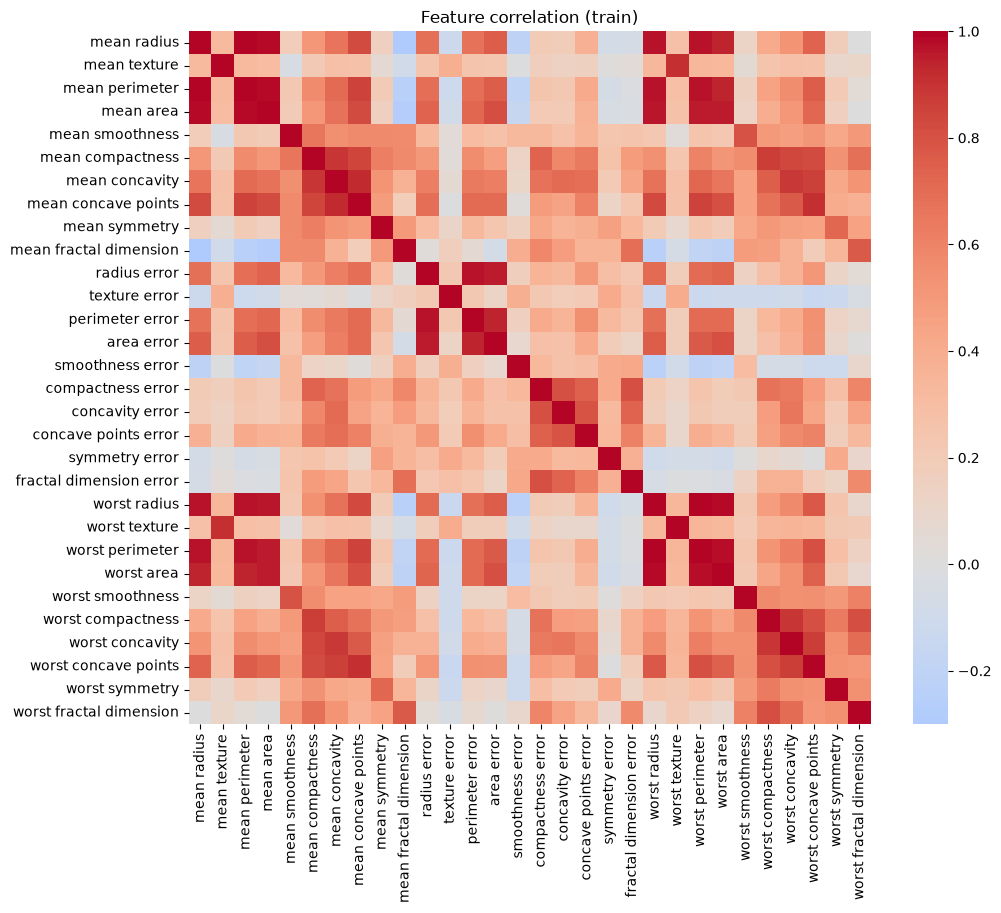

|r| > 0.95 的特徵對：15 組


,,r
mean radius,mean perimeter,0.997789
worst radius,worst perimeter,0.993478
mean radius,mean area,0.988886
mean perimeter,mean area,0.987834
worst radius,worst area,0.985890
worst perimeter,worst area,0.978738
mean perimeter,worst perimeter,0.970918
radius error,perimeter error,0.970870
mean radius,worst radius,0.970133
mean perimeter,worst radius,0.969674


In [6]:
# 共線性：特徵之間的相關係數
# 觀察：|r| > 0.95 的特徵對共 15 組，來源有兩種：
#   (a) 幾何關係：perimeter ≈ 2πr、area ≈ πr²，三者都由半徑決定（實測 perimeter / 2πr 平均 1.03、標準差 0.02）。
#       area 與 r 是平方關係，相關仍達 0.99，因為在半徑的實際範圍內 r² 近似線性。
#       radius error、perimeter error、area error 之間的高相關是同一關係在標準誤上的翻版。
#   (b) 同一測量的不同統計量：mean 與 worst 同向變動（例如 mean radius vs worst radius = 0.97）。
#   heatmap 另有一個中高度相關的區塊：compactness、concavity、concave points（r ≈ 0.84–0.92），都在描述輪廓的不規則程度。
#   → 嚴重共線性：個別係數不穩定、不能逐一解讀，但不影響預測（見 TODO 1 (3)）。
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Feature correlation (train)")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r")
print(f"|r| > 0.95 的特徵對：{(upper.abs() > 0.95).sum()} 組")
display(upper[upper.abs() > 0.95].sort_values(ascending=False).to_frame())

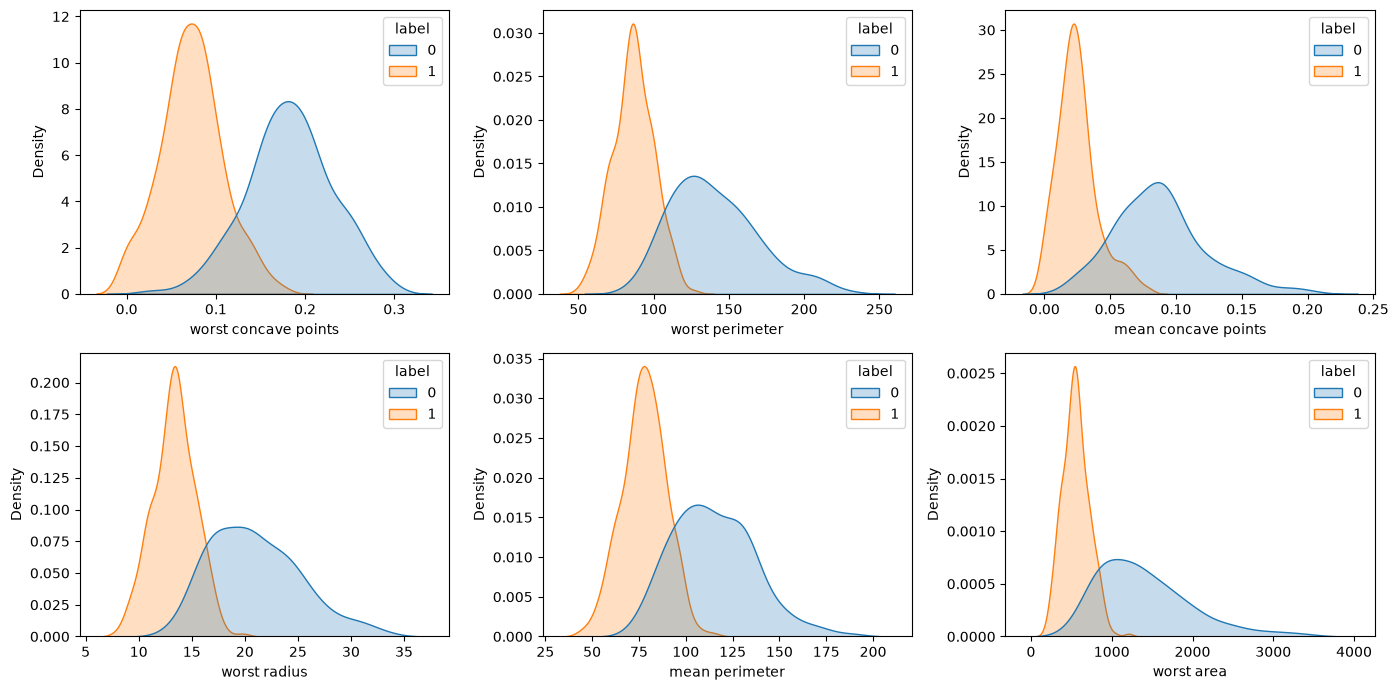

In [7]:
# 與標籤最相關的 6 個特徵，在兩類中的分布
# 觀察：6 個特徵呈現同一型態 —— 惡性（0）位於較高的值且分布較寬，良性（1）集中在低值且較窄。
#   例：worst perimeter 惡性 140 ± 29、良性 87 ± 13（平均 ± 標準差）。
#   - 兩類在交界處有重疊 → 任何單一特徵都無法完全分開，需要組合多個特徵。
#   - 分布是單調位移（越大越惡性），沒有「中間一類、兩側另一類」的型態 → 線性決策邊界是合理的假設。
#   - 6 個特徵有 4 個是大小類（perimeter、radius、area），彼此高度共線，提供的資訊大量重複。
top6 = train.corr()["label"].drop("label").abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.kdeplot(data=train, x=col, hue="label", common_norm=False, fill=True, ax=ax)
fig.tight_layout()
plt.show()

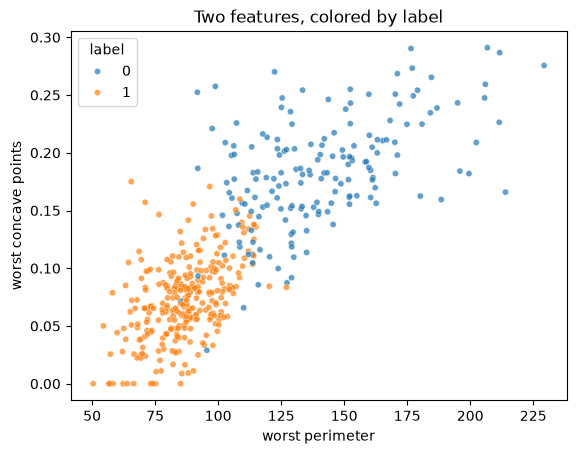

In [8]:
# 只用兩個特徵，兩類能用一條直線分開嗎？
# 觀察：兩群大致位於一條斜線的兩側：右上（周長大、凹點多）為惡性，左下為良性。
#   無法用一條直線「完全」分開，但只用這兩個特徵，幾乎不正則化的邏輯回歸已能分對約 94% 的訓練樣本
#   （455 筆錯 26 筆），錯誤集中在兩群交界的重疊區。
#   重疊來自資料本身（兩類在這兩個特徵上確實有相同的值），換成彎曲的邊界也無法消除。
#   使用全部 30 個特徵時，標準化後的訓練集是完全線性可分的（TODO 8 會驗證）。
sns.scatterplot(data=train, x="worst perimeter", y="worst concave points", hue="label", s=20, alpha=0.7)
plt.title("Two features, colored by label")
plt.show()

### TODO 1（問答）EDA 小結

> **(1)** 兩類的比例是多少？如果一個模型永遠猜「良性」，accuracy 會是多少？這對解讀 accuracy 有什麼影響？

良性 62.6%、惡性 37.4%（約 1.7 : 1）。永遠猜良性的 accuracy = 0.626（測試集 72/114 = 0.632）。

影響：

- accuracy 的起點是 0.626 而不是 0.5，評估模型時要和這個 baseline 比較，而非看絕對數字。
- accuracy 不區分錯在哪一類：「永遠猜良性」有 0.626 的 accuracy，但惡性 recall = 0（所有惡性全部漏掉）。在兩種錯誤代價不對稱的醫療情境，必須另外看惡性的 recall／precision。
- 1.7 : 1 屬於輕度不平衡，不需要重抽樣；主要靠分層切分（stratify）與選對指標處理。

> **(2)** 特徵的尺度差多少（看 describe 的 mean／max）？對梯度下降與正則化各有什麼影響？（連結第二章）

平均值從 0.0038 到 869，相差約 $2\times10^5$ 倍。

- **梯度下降**：尺度差異使 Hessian 的條件數 $\kappa$ 極大。學習率上限由最陡（大尺度特徵）的方向決定（$\text{lr} < 2/\lambda_\max$），最平緩（小尺度特徵）的方向每步幾乎不動，收斂步數約與 $\kappa$ 成正比 → 影響的是收斂「速度」，只要學習率不超過上限，最終仍收斂到同一個解。
- **正則化**：L2 懲罰 $\lambda\|w\|^2$ 對每個係數罰得一樣重，但係數大小取決於特徵尺度 —— 大尺度特徵（area ~$10^3$）只需很小的 $w$，幾乎不受懲罰；小尺度特徵（smoothness ~0.1）需要大 $w$，被不成比例地重罰。收縮程度變成由任意的單位決定，而非由特徵的重要性決定。

兩者的解法都是標準化（在訓練集 fit scaler，用 Pipeline 包起來）；正則化本身不能修正尺度問題。

> **(3)** mean radius、mean perimeter、mean area 的相關係數接近 1，從幾何上怎麼解釋？這種共線性對「係數的解讀」會有什麼影響？

**幾何**：$\text{perimeter} \approx 2\pi r$、$\text{area} \approx \pi r^2$，三者都是半徑的函數（細胞核近似圓形）。area 雖是 $r$ 的平方，但在實際的半徑範圍內 $r^2$ 近似線性，所以相關仍達 0.99。

**影響**：

- 模型無法分辨預測力該歸給 radius、perimeter 還是 area，個別係數的變異很大、對資料微小變動很敏感，可能出現一正一負互相抵消，正負號甚至與單變量相關係數相反。
- 因此不能把單一係數解讀為「該特徵的效果」（其他特徵固定時，radius 變大而 perimeter 不變在現實中不會發生）。
- 不影響的部分：預測值幾乎不受影響；加了 L2 的邏輯回歸是嚴格凸函數，最佳解唯一且找得到。不加正則化時，近乎奇異的 Hessian 會讓求解變慢、係數更不穩定 —— L2 正則化可以緩解。

> **(4)** 從 KDE 和散點圖看，線性分界（邏輯回歸的決策邊界是一個超平面）合理嗎？
>
> （題意：決策邊界 $w \cdot x + b = 0$ 在二維是一條直線、在 30 維是一個超平面，不能彎曲。）

合理：

- KDE：重要特徵都是「越大越惡性」的單調位移，沒有需要彎曲邊界的型態（例如中間一類、兩側另一類）。
- 散點圖：只用兩個特徵，一條直線就分對約 94%，錯誤集中在兩群的重疊區；重疊是資料本身的雜訊，換成任何形狀的邊界都無法消除，所以不是「線性不夠用」的證據。
- 30 個特徵一起看，標準化後的訓練集甚至完全線性可分（TODO 8）。

預期：邏輯回歸在這份資料上應有很高的準確率，主要風險在共線性造成的係數不穩定，而非模型容量不足。

---
## 2. Baseline

先用「不看特徵」的 Dummy 模型算出交叉驗證分數，之後的模型至少要明顯贏過它。
同時看三種指標：

- **accuracy**：猜對的比例（只看 0/1 的預測）
- **ROC AUC**：把「良性機率」排序，隨機抽一個良性、一個惡性，良性排在前面的機率（只看排序）
- **log loss**（交叉熵）：機率預測的品質，越低越好；sklearn 的 scoring 用 `neg_log_loss`（負號，越高越好）

In [10]:
from sklearn.base import BaseEstimator
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 整章共用的 5-fold（分層、打亂、固定 seed），所有 CV 分數才能互相比較
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {"log_loss": "neg_log_loss", "accuracy": "accuracy", "roc_auc": "roc_auc"}


def cv_summary(
    model: BaseEstimator, X: pd.DataFrame = X_train, y: pd.Series = y_train
) -> dict[str, str]:
    """5-fold CV。

    回傳 {"log_loss": "平均 ± 標準差", "accuracy": ..., "roc_auc": ...}；log_loss 已轉回正值（越低越好）。
    """
    s = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    out = {}
    for k in SCORING:
        v = s[f"test_{k}"] * (-1 if k == "log_loss" else 1)
        out[k] = f"{v.mean():.4f} ± {v.std():.4f}"
    return out


baseline = pd.DataFrame({
    "Dummy most_frequent": cv_summary(DummyClassifier(strategy="most_frequent")),
    "Dummy prior": cv_summary(DummyClassifier(strategy="prior")),
}).T
display(baseline)

,log_loss,accuracy,roc_auc
Dummy most_frequent,13.4669 ± 0.0000,0.6264 ± 0.0000,0.5000 ± 0.0000
Dummy prior,0.6609 ± 0.0000,0.6264 ± 0.0000,0.5000 ± 0.0000


### TODO 2（問答）

> **(1)** 兩個 Dummy 的 accuracy 一樣、ROC AUC 都是 0.5，為什麼 log loss 差這麼多（約 13 vs 0.66）？
>
> 提示：most_frequent 的 predict_proba 輸出什麼？log(0) 會怎樣？

兩者都不看特徵，對每一筆樣本輸出同一組機率；差別在機率本身：

| 策略 | `predict_proba` | 意思 |
| --- | --- | --- |
| most_frequent | 恆為 `[0, 1]` | $P(\text{benign}) = 1$、$P(\text{malignant}) = 0$（100% 確定是良性） |
| prior | 恆為 `[0.374, 0.626]` | 訓練集的類別比例 |

兩者 predict 都是「良性」，所以 accuracy 相同（0.626）。

log loss 只看「正確類別被給了多少機率」：每筆的 loss $= -\log P(\text{正確類別})$。

- most_frequent：良性樣本 $-\log 1 = 0$；惡性樣本 $-\log 0 = \infty$。sklearn 把機率裁切到 $[\varepsilon, 1 - \varepsilon]$（$\varepsilon = 2.2\times10^{-16}$），所以每筆惡性的 loss $= -\log\varepsilon \approx 36.04$，平均 $= 0.374 \times 36.04 \approx 13.47$。
- prior：每筆最多只付 $-\log 0.374 \approx 0.98$，不會出現極端懲罰。

結論：log loss 嚴懲「很有把握地錯」，信心 100% 卻答錯的代價是無限大；accuracy 只看 0/1 的預測，完全感受不到信心程度的差異。

（注意：prior 並沒有計算任何條件機率 $P(y \mid x)$，它不看 $x$，對每筆都輸出同一個先驗分布。）

> **(2)** prior 的 log loss ≈ 0.66 這個數字可以手算出來，用訓練集的類別比例算算看。

設良性比例 $q = 285/455 = 0.626$。prior 對每筆都預測 $P(\text{benign}) = q$：

- 良性樣本（佔 $q$）：loss $= -\ln q = -\ln 0.626 \approx 0.468$
- 惡性樣本（佔 $1-q$）：loss $= -\ln(1-q) = -\ln 0.374 \approx 0.984$

$$\text{平均 log loss} = -[q \ln q + (1-q)\ln(1-q)] = 0.626 \times 0.468 + 0.374 \times 0.984 \approx 0.661$$

- 這正是標籤分布的熵（entropy，以 nat 為單位）—— 不看任何特徵時，log loss 能達到的最小值。
- 它是 log loss 的實際 baseline：模型要低於 0.66，才代表特徵提供了資訊。
- （CV 的 0.6609 與手算略有差異，因為每個 fold 用該 fold 訓練資料的比例。）

> **(3)** 為什麼 ROC AUC 是 0.5？

**定義**：ROC AUC = 把所有「一個良性 × 一個惡性」的配對都比一遍，良性分數高於惡性的比例（平手記 0.5）。「隨機抽一個良性、一個惡性，良性排在前面的機率」是同一件事的機率說法。

**小例子**（分數 = $P(\text{benign})$）：良性 A 0.9、B 0.8、C 0.4；惡性 D 0.6、E 0.1

| 配對 | A–D | A–E | B–D | B–E | C–D | C–E |
| --- | --- | --- | --- | --- | --- | --- |
| 良性排前面？ | ✓ | ✓ | ✓ | ✓ | ✗ | ✓ |

共 3 × 2 = 6 組，AUC = 5/6 ≈ 0.83。本訓練集是 285 × 170 = 48,450 組配對，算法相同。

- Dummy 對每筆樣本都輸出 0.626，所有配對都是平手、各記 0.5 分，因此 AUC = 0.5。
- 從曲線看：門檻掃過時，所有樣本同時被判為正類或負類，ROC 只有 (0,0) 和 (1,1) 兩點，連線就是對角線，下方面積 0.5。（ROC 曲線下面積與「配對排對的比例」在數學上等價。）

**性質**：

- 只看排序、不看分數大小：上例分數全部除以 2，排序不變，AUC 仍是 0.83；機率準不準是 log loss 的工作。
- 不需要選門檻：一次評估所有可能的門檻（accuracy 則要先選定門檻，預設 0.5）。
- 與類別比例無關 —— 這也是為什麼兩個 Dummy 的 AUC 相同。

**解讀**：1.0 = 存在門檻能完美分開；0.5 = 完全不會排序（baseline）；< 0.5 = 排序方向顛倒。

---
## 3. 手寫模型

### 3A. Sigmoid 與交叉熵

模型：z = w·x + b，p = P(y=1 | x) = σ(z) = 1 / (1 + e⁻ᶻ)

Loss（平均交叉熵 + L2 正則化）：

J(w, b) = −(1/n) Σ [ yᵢ log pᵢ + (1 − yᵢ) log(1 − pᵢ) ] + (λ/2)‖w‖²

- 取 **λ = 1 / (C·n)**，就跟 sklearn `LogisticRegression(C=C)` 的目標函數只差一個常數倍（sklearn：C·Σ CE + ½‖w‖²），最佳解相同，可以直接比對係數。
- bias **不**懲罰（跟第二章 Ridge 一樣）。

數值穩定是這一節的重點：直接照公式寫，z 很大或很小時會出現 overflow 或 log(0)。

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.typing import ArrayLike
from sklearn.preprocessing import StandardScaler
from ml_dl_llm.data import load_breast_cancer
from ml_dl_llm.metrics import classification_metrics

X_train, X_test, y_train, y_test = load_breast_cancer()
feature_names = X_train.columns.tolist()

# 只用訓練集 fit scaler，再套到測試集（避免資料洩漏）
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)
y_tr = y_train.to_numpy(dtype=float)  # 手寫模型用 numpy


def add_bias(X: ArrayLike) -> np.ndarray:
    """在 X 最左邊補一欄 1，讓 bias 變成係數向量的第 0 個元素。X (n, d) → (n, d + 1)。"""
    X = np.asarray(X, dtype=float)
    return np.c_[np.ones(len(X)), X]


def sigmoid(z: ArrayLike) -> np.ndarray:
    """數值穩定的 sigmoid，逐元素計算；回傳與 z 同 shape、值在 (0, 1) 的陣列。"""
    z = np.asarray(z, dtype=float)
    # TODO 3（程式）：σ(z) = 1 / (1 + e⁻ᶻ)，但任何 z 都不能 overflow
    #   - 直接寫 1 / (1 + np.exp(-z))：z = -1000 時 np.exp(1000) overflow
    #   - 提示：e = np.exp(-np.abs(z)) 一定 ≤ 1；z ≥ 0 用 1 / (1 + e)，z < 0 用 e / (1 + e)（為什麼兩者相等？）
    #   - 用 np.where 一次處理整個陣列，不要寫 for 迴圈
    e = np.exp(-np.abs(z))
    out = np.where(z >= 0, 1 / (1 + e), e / (e + 1))
    return out


def bce_from_logits(z: ArrayLike, y: ArrayLike) -> float:
    """平均二元交叉熵，直接從 z（logit）算，不先算 p。z、y 都是 (n,)，y ∈ {0, 1}；回傳純量。"""
    z = np.asarray(z, dtype=float)
    y = np.asarray(y, dtype=float)
    # TODO 4（程式）：−[y log σ(z) + (1 − y) log(1 − σ(z))] 的平均
    #   - 先在紙上證明：−[y log σ(z) + (1 − y) log(1 − σ(z))] = log(1 + eᶻ) − y·z
    #   - log(1 + eᶻ) 用 np.logaddexp(0, z) 算（= log(e⁰ + eᶻ)，內部已處理 overflow）
    loss = (-z * y + np.logaddexp(0, z)).mean()
    return loss

In [13]:
from scipy.special import expit
from sklearn.metrics import log_loss

z = np.linspace(-1000, 1000, 20001)
with np.errstate(over="raise", divide="raise"):  # 有 overflow／除以 0 會直接報錯
    s = sigmoid(z)
    print("✅ sigmoid 與 scipy.special.expit 最大差異：", np.abs(s - expit(z)).max(), "（應 < 1e-15）")

    rng = np.random.default_rng(0)
    z_mid = rng.normal(scale=3, size=1000)
    y_mid = rng.integers(0, 2, size=1000)
    print("✅ bce 與 sklearn log_loss 差異    ：",
          abs(bce_from_logits(z_mid, y_mid) - log_loss(y_mid, expit(z_mid))), "（應 < 1e-12）")
    print("✅ 極端值：bce(z=[1000, -1000], y=[0, 1]) =", bce_from_logits([1000, -1000], [0, 1]), "（應 = 1000，不是 inf／nan）")

# 對照：naive 寫法先算 p 再取 log
with np.errstate(over="ignore", divide="ignore"):
    p_naive = 1 / (1 + np.exp(-np.array([1000.0, -1000.0])))
    print("naive：p =", p_naive, " loss =", -np.mean([np.log(1 - p_naive[0]), np.log(p_naive[1])]))

✅ sigmoid 與 scipy.special.expit 最大差異： 5.551115123125783e-17 （應 < 1e-15）
✅ bce 與 sklearn log_loss 差異    ： 0.0 （應 < 1e-12）
✅ 極端值：bce(z=[1000, -1000], y=[0, 1]) = 1000.0 （應 = 1000，不是 inf／nan）
naive：p = [1. 0.]  loss = inf


### 3B. 梯度下降（Gradient Descent）

先在紙上推一次梯度。提示：σ′(z) = σ(z)(1 − σ(z))，推完會發現形式跟第二章線性回歸的 MSE 梯度幾乎一樣。

`loss_grad` 單獨寫成一個方法，等一下用**數值梯度**檢查它對不對（實作任何新模型時都很好用的除錯技巧）。

In [14]:
from typing import Self


class LogisticRegressionGD:
    """Full-batch 梯度下降，最小化平均交叉熵 + (λ/2)‖w‖²，λ = 1/(C·n)。C=None 表示不正則化。"""

    def __init__(
        self,
        lr: float = 1.0,
        n_epochs: int = 10000,
        C: float | None = 1.0,
        tol: float = 1e-8,
    ) -> None:
        self.lr = lr
        self.n_epochs = n_epochs
        self.C = C
        self.tol = tol  # 梯度範數小於 tol 就提早停（tol=0 表示一定跑滿 n_epochs）

    def loss_grad(
        self, X: np.ndarray, y: np.ndarray, w: np.ndarray, b: float, lam: float
    ) -> tuple[float, np.ndarray, float]:
        """X (n, d)、y (n,)、w (d,)。回傳 (loss 純量, grad_w (d,), grad_b 純量)。"""
        n = len(y)
        z = X @ w + b
        # TODO 5（程式）：loss 與梯度
        #   loss  ：bce_from_logits + (λ/2)‖w‖²（純量）
        #   grad_w：shape (d,)，記得加上正則化項的梯度
        #   grad_b：純量（bias 不懲罰）
        #   提示：先算 r = σ(z) − y，再用矩陣運算，不要寫 for 迴圈
        loss = bce_from_logits(z, y) + (lam / 2) * (w.T @ w)
        residual = sigmoid(z) - y
        grad_w = X.T @ residual / n + lam * w
        grad_b = residual.mean()
        return loss, grad_w, grad_b

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,) ∈ {0, 1}。學到 w_ (d,)、b_ 與每個 epoch 的紀錄，回傳 self。"""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        lam = 0.0 if self.C is None else 1.0 / (self.C * n)
        self.w_ = np.zeros(d)
        self.b_ = 0.0
        self.loss_history_, self.grad_norm_history_, self.w_norm_history_ = [], [], []

        for epoch in range(self.n_epochs):
            loss, grad_w, grad_b = self.loss_grad(X, y, self.w_, self.b_, lam)
            # TODO 6（程式）：參數更新（兩行）
            self.w_ -= grad_w * self.lr
            self.b_ -= grad_b * self.lr

            self.loss_history_.append(loss)
            self.grad_norm_history_.append(np.sqrt(grad_w @ grad_w + grad_b**2))
            self.w_norm_history_.append(np.linalg.norm(self.w_))
            if not np.isfinite(loss):  # 發散就停
                break
            if self.grad_norm_history_[-1] < self.tol:
                break
        return self

    def decision_function(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的 logit z = Xw + b。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict_proba(self, X: ArrayLike) -> np.ndarray:
        """跟 sklearn 一樣回傳 (n, 2)：第 0 欄 P(y=0)、第 1 欄 P(y=1)。"""
        p = sigmoid(self.decision_function(X))
        return np.c_[1 - p, p]

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的 0／1 預測（z ≥ 0 判 1）。"""
        return (self.decision_function(X) >= 0).astype(int)

In [15]:
# 數值梯度檢查：用中央差分 (J(θ+ε) − J(θ−ε)) / 2ε 近似每個偏微分，跟解析梯度比
rng = np.random.default_rng(0)
w0, b0, lam0, eps = rng.normal(size=X_train_s.shape[1]), 0.3, 0.01, 1e-6
model = LogisticRegressionGD()


def J(w: np.ndarray, b: float) -> float:
    """固定資料與 λ，只把 loss 當成 (w, b) 的函數。"""
    return model.loss_grad(X_train_s, y_tr, w, b, lam0)[0]


_, gw, gb = model.loss_grad(X_train_s, y_tr, w0, b0, lam0)
num_gw = np.array(
    [(J(w0 + eps * e, b0) - J(w0 - eps * e, b0)) / (2 * eps) for e in np.eye(len(w0))]
)
num_gb = (J(w0, b0 + eps) - J(w0, b0 - eps)) / (2 * eps)

analytic, numeric = np.r_[gw, gb], np.r_[num_gw, num_gb]
rel_err = np.linalg.norm(analytic - numeric) / np.linalg.norm(analytic + numeric)
print(f"✅ 梯度相對誤差：{rel_err:.2e}（應 < 1e-7；> 1e-4 通常代表梯度寫錯）")

✅ 梯度相對誤差：2.68e-10（應 < 1e-7；> 1e-4 通常代表梯度寫錯）


epochs： 5050   final loss： 0.06548944245799804
✅ w 與 sklearn 的最大差異： 2.1094338910065957e-06 （應 < 1e-5）
✅ b 與 sklearn 的差異    ： 6.80679403064488e-07 （應 < 1e-5）
train accuracy： 0.989010989010989


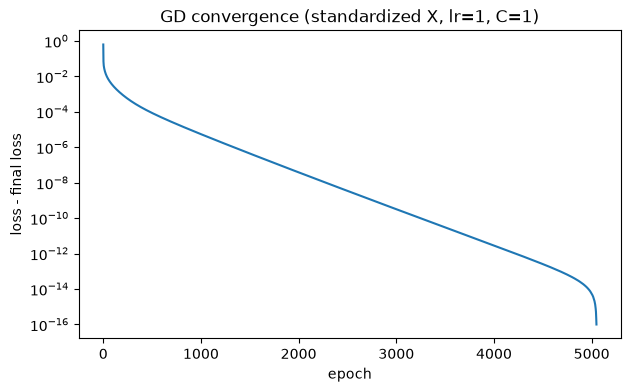

In [16]:
from sklearn.linear_model import LogisticRegression

gd = LogisticRegressionGD(lr=1.0, n_epochs=20000, C=1.0).fit(X_train_s, y_tr)
# 參考答案：sklearn 用 lbfgs 求解同一個目標函數，tol 調小讓它解得夠精確
sk_ref = LogisticRegression(C=1.0, tol=1e-10, max_iter=10000).fit(X_train_s, y_train)

print("epochs：", len(gd.loss_history_), "  final loss：", gd.loss_history_[-1])
print(
    "✅ w 與 sklearn 的最大差異：",
    np.abs(gd.w_ - sk_ref.coef_[0]).max(),
    "（應 < 1e-5）",
)
print(
    "✅ b 與 sklearn 的差異    ：", abs(gd.b_ - sk_ref.intercept_[0]), "（應 < 1e-5）"
)
print("train accuracy：", (gd.predict(X_train_s) == y_train).mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.maximum(np.array(gd.loss_history_) - min(gd.loss_history_), 1e-16))
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("loss - final loss")
ax.set_title("GD convergence (standardized X, lr=1, C=1)")
plt.show()

,data,lr,final_loss,max_loss,train_acc
0,scaled,0.01,0.085547,6.931472e-01,0.986813
1,scaled,0.10,0.066388,6.931472e-01,0.989011
2,scaled,1.00,0.065489,6.931472e-01,0.989011
3,scaled,10.00,0.065489,1.069703e+00,0.989011
4,raw,0.01,27.959182,2.409727e+03,0.920879
5,raw,0.10,8067.953258,2.420874e+04,0.745055
6,raw,1.00,37663.527462,2.505318e+05,0.760440
7,raw,10.00,144912.008621,2.575428e+06,0.382418


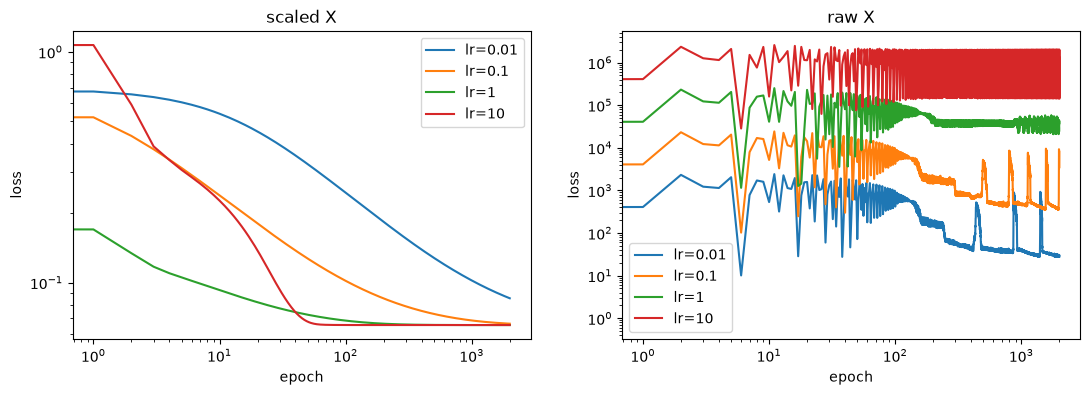

In [17]:
# 實驗 1：學習率 × 是否標準化（固定跑 2000 epochs，不提早停）
rows, curves = [], {}
with np.errstate(over="ignore", invalid="ignore"):
    for data_name, X in [("scaled", X_train_s), ("raw", X_train.to_numpy())]:
        for lr in [0.01, 0.1, 1, 10]:
            m = LogisticRegressionGD(lr=lr, n_epochs=2000, C=1.0, tol=0).fit(X, y_tr)
            curves[(data_name, lr)] = m.loss_history_
            rows.append(
                {
                    "data": data_name,
                    "lr": lr,
                    "final_loss": m.loss_history_[-1],
                    "max_loss": max(m.loss_history_),
                    "train_acc": (m.predict(X) == y_train).mean(),
                }
            )
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, data_name in zip(axes, ["scaled", "raw"]):
    for lr in [0.01, 0.1, 1, 10]:
        ax.plot(curves[(data_name, lr)], label=f"lr={lr}")
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.set_title(f"{data_name} X")
    ax.legend()
plt.show()

### TODO 7（問答）

> **(1)** 第二章線性回歸在 $\text{lr} > 2/\lambda_\max$ 時 loss 會爆到 inf。這裡 scaled、lr=10 有發散到 inf 嗎？曲線長什麼樣？為什麼邏輯回歸的梯度下降比較「耐」大學習率？
>
> 提示：看 TODO 5 的梯度，$|\sigma(z) - y|$ 最大是多少？Hessian 裡的 $\sigma(1-\sigma)$ 在 $|z|$ 很大時趨近多少？

沒有發散。lr=10 第 1 步 loss 由 0.693 升到 1.07（走過頭），之後持續下降，最終與 lr=1 相同（0.0655），甚至更早降到 0.07 以下（第 46 vs 74 個 epoch）。

用第二章的二次近似算上限：起點 $w = 0$ 時 $p = 0.5$，Hessian $= 0.25 \cdot X_b^\top X_b / n$，$\lambda_\max \approx 3.33$ → $2/\lambda_\max \approx 0.60$。lr=1 與 lr=10 都超過這個上限，線性回歸早就發散了，這裡卻都收斂。原因：

① **梯度有界**：$\nabla_w = X^\top(\sigma(z) - y)/n$，而 $|\sigma(z) - y| < 1$，不論參數多離譜，梯度大小都不超過 $\max_i\|x_i\|$（加上很小的 $\lambda w$）。線性回歸的殘差 $\hat{y} - y$ 沒有上界，誤差越大梯度越大，每步誤差乘上 $|1 - \text{lr}\cdot\lambda| > 1$ → 指數爆炸。邏輯回歸一步走太遠，只是「走過頭一段有限的距離」，不會自我放大。

② **曲率會自己變小**：Hessian 的權重 $\sigma(z)(1 - \sigma(z))$ 在 $|z|$ 大時趨近 0。走過頭讓 $|z|$ 變大 → 局部 $\lambda_\max$ 變小 → 穩定上限 $2/\lambda_\max$ 自動放寬。二次函數（線性回歸）的曲率處處相同，沒有這種機制。

③ 遠離最佳解時 loss 只隨 $|z|$ 線性成長（$\log(1 + e^z) \approx z$），而非平方成長 —— 這是「log 把大數壓下來」這個直覺的精確版本，但它是結果；真正的原因是 ①②。

注意：這不代表 lr 可以任意大。二次的正則化項 $\frac{\lambda}{2}\|w\|^2$ 仍要求 $\text{lr} < 2/\lambda$（≈ 910），而且走過頭時 loss 會先上升，lr 太大時前期會劇烈震盪（見 (2) 的 raw）。

> **(2)** raw 資料（沒標準化）各學習率的表現如何？跟第二章的結論一樣嗎？

raw 的初始二次穩定上限 $2/\lambda_\max \approx 5\times10^{-6}$（由 area ~$10^3$ 這類大尺度特徵決定），測試的 lr（≥ 0.01）都超過 2000 倍以上：

- loss 第一步就衝到數百～數百萬，$|z|$ 最大到 $3\times10^4$；之後劇烈震盪，lr=0.01 只有約一半的步數讓 loss 下降。
- 因為梯度有界（(1) 的 ①），loss 不會變成 inf，而是在很大的值之間來回跳。
- 2000 epochs 後 train accuracy 只有 0.38～0.92，全部不如標準化（0.99）。
- 補充實驗：lr 降到 1e-6（低於上限）就不再震盪，但 2000 epochs 後 loss 仍約 0.39 —— 穩定卻慢到不可用。

與第二章比較：

- 結論相同：沒有標準化，梯度下降不可用，必須先標準化。
- 表現不同：線性回歸是指數發散到 inf；邏輯回歸是有界的震盪，不會變 inf，但同樣學不好。

「取決於條件數」要拆成兩件事：

- loss 衝高、震盪 → lr 超過 $2/\lambda_\max$，是 $\lambda_\max$（最陡方向）的問題。
- lr 降到穩定範圍後收斂極慢 → 最平緩方向幾乎不動，步數約與 $\kappa = \lambda_\max/\lambda_\min$ 成正比，這才是條件數的問題（raw $\kappa \approx 2\times10^{12}$，標準化後 $\approx 1\times10^5$）。

另外：raw 的震盪對浮點誤差很敏感，同一份程式在不同電腦上的 final_loss 可能不同，scaled 則不會。

無正則化：train accuracy = 1.0   final loss = 7.67e-03   ‖w‖ = 98.2   max|z| = 334.9
C = 1   ：train accuracy = 0.989010989010989   ‖w‖ = 3.59


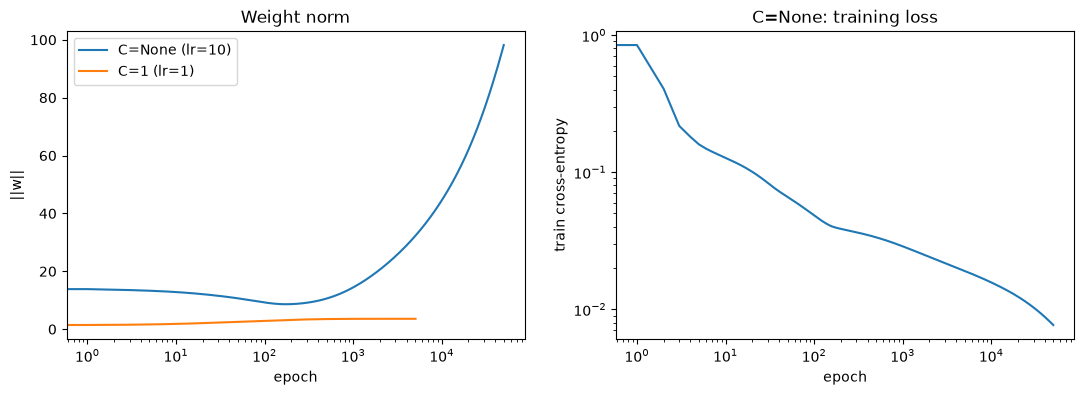

In [18]:
# 實驗 2：不加正則化（C=None）會怎樣？
free = LogisticRegressionGD(lr=10.0, n_epochs=50000, C=None, tol=0).fit(
    X_train_s, y_tr
)  # 跑比較久，約數秒
print(
    "無正則化：train accuracy =",
    (free.predict(X_train_s) == y_train).mean(),
    "  final loss =",
    f"{free.loss_history_[-1]:.2e}",
    "  ‖w‖ =",
    round(free.w_norm_history_[-1], 1),
    "  max|z| =",
    round(np.abs(free.decision_function(X_train_s)).max(), 1),
)
print(
    "C = 1   ：train accuracy =",
    (gd.predict(X_train_s) == y_train).mean(),
    "  ‖w‖ =",
    round(gd.w_norm_history_[-1], 2),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(free.w_norm_history_, label="C=None (lr=10)")
axes[0].plot(gd.w_norm_history_, label="C=1 (lr=1)")
axes[0].set_xscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("||w||")
axes[0].legend()
axes[0].set_title("Weight norm")
axes[1].plot(free.loss_history_)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("train cross-entropy")
axes[1].set_title("C=None: training loss")
plt.show()

### TODO 8（問答）

> **(1)** 訓練集 accuracy 是多少？這代表訓練資料有什麼性質？

無正則化：train accuracy = 1.0 → 標準化後的訓練集（30 維）是「線性可分」的：存在一個超平面把兩類完全分開。

C = 1 的 train accuracy 是 0.989（錯 5 筆）。這是 L2 刻意的取捨：用一點訓練誤差換取較小的 $\|w\|$，不代表模型比較差 —— 在測試集上（另外驗證）：

| | test accuracy | test log loss | 單筆最大 loss |
| --- | --- | --- | --- |
| 無正則化 | 0.930 | 1.02（比 Dummy prior 的 0.66 還差） | 31 |
| C = 1 | 0.982 | 0.078 | 2.4 |

無正則化的 $\max|z| = 335$，等於對每筆都輸出接近 0 或 1 的機率；一旦在測試集上錯，就是「極有把握地錯」，log loss 被少數樣本主導（TODO 2 的 $\log 0$ 問題）。這就是過擬合：訓練集完美，機率卻完全不可信。

> **(2)** 為什麼不加正則化時 $\|w\|$ 會一直變大、loss 一直往 0 逼近卻永遠到不了？最大概似估計（MLE）存在嗎？
>
> 提示：資料線性可分時，把 $w$ 乘上 2 倍，分界線變了嗎？每個樣本的 loss 變大還是變小？

設 $(w, b)$ 已把訓練集完全分對，每筆的 margin $m_i = (2y_i - 1) \cdot z_i > 0$，單筆 loss $= \log(1 + e^{-m_i})$。把 $(w, b)$ 乘上 $c > 1$：

- 分界線 $\{x : w \cdot x + b = 0\}$ 不變 → 預測不變、accuracy 不變；
- 每個 margin 變成 $c \cdot m_i$，更大 → 每筆 loss 嚴格變小（實測 $c = 2$ 時平均 loss 0.0077 → 0.0029）。

所以永遠可以靠「放大 $w$」讓 loss 再小一點：loss 的下確界是 0，但只有 $\|w\| \to \infty$ 時才逼近，任何有限的 $w$ 都達不到。

→ **MLE 不存在**（沒有有限的最小值點）。梯度下降會讓 $\|w\|$ 無止境地成長，但越來越慢：margin 越大，$\sigma(z) - y$ 越接近 0，梯度呈指數變小。

- （延伸：理論上 $w$ 的「方向」會收斂到最大間隔分界線，也就是 hard-margin SVM 的解 —— 學到 07-svm 時會再遇到。）
- 另外，只要資料線性可分，這個問題與學習率、迭代次數無關；在特徵數多、樣本少時特別常見。

> **(3)** 加上 L2 正則化之後為什麼 $\|w\|$ 會停下來？用「兩股力量的平衡」說明。這跟第一章感知器「線性可分就停止更新」有什麼不同？

兩股力量（梯度 = 0 的條件）：

$$\frac{1}{n} X^\top(\sigma(z) - y) + \lambda w = 0$$

- 交叉熵：把 $w$ 往「放大」推，以增加 margin。但它的推力隨 margin 增加而指數衰減（$\propto e^{-\text{margin}}$）。
- L2 懲罰：把 $w$ 往 0 拉，拉力 $\lambda w$ 隨 $\|w\|$ 線性增加。

推力越來越弱、拉力越來越強，兩者必在某個有限的 $\|w\|$ 相等（本例 $\|w\| \approx 3.59$）。加了 L2 的目標函數是嚴格凸函數 → 最佳解存在且唯一，與起始值無關。

- 注意：L2 不做變數選擇（那是 L1／Lasso 的性質，係數會被壓成恰為 0）；L2 只把所有係數一起縮小、不會歸零。
- 它也不是「提早停下」：GD 是收斂到一個明確的最佳解；「訓練到一半就停」（early stopping）是另一種隱式正則化。

與感知器的差別：

- 感知器的 loss 只看「有沒有分錯」：一旦全部分對，loss = 0、不再更新，停在「第一個找到的」分界線，結果取決於初始值與樣本順序，也沒有「多有把握」的概念。
- 邏輯回歸即使全部分對，loss 仍 > 0，會持續推大 margin：不加正則化 → $\|w\|$ 發散；加 L2 → 停在 margin 與 $\|w\|$ 取得平衡的唯一解，並輸出有意義的機率。

### 3C. 牛頓法（Newton's method／IRLS）

梯度下降只用一階資訊（斜率）；牛頓法再用二階資訊（曲率）決定每一步走多遠、往哪走：

θ ← θ − H⁻¹ ∇J

邏輯回歸的 Hessian（θ 含 bias，Xb 是補了 1 的 X）：

H = (1/n) Xbᵀ S Xb + λI′，S = diag(pᵢ(1 − pᵢ))，I′ 是 bias 那格為 0 的單位矩陣

對照第二章：線性回歸的 Hessian 是 (2/n)XᵀX，跟參數無關；這裡多了隨 p 變化的權重 S。

迭代次數： 10
✅ 最後的梯度範數： 4.278240777796004e-14 （應 < 1e-10，約 10 次迭代內）
✅ w 與 sklearn 的最大差異： 6.3742232253583e-07 （應 < 1e-5）
   w 與手寫 GD 的最大差異  ： 1.8842252841322349e-06


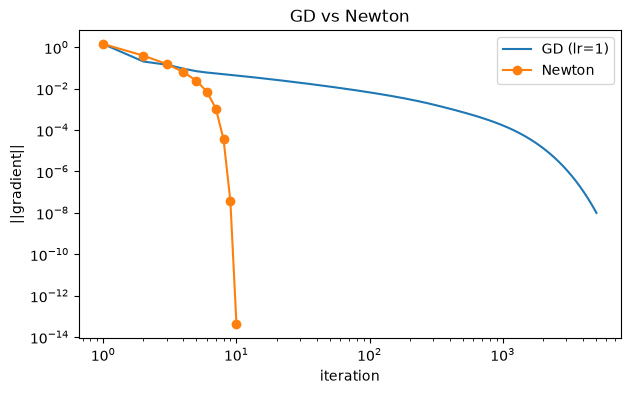

In [19]:
class LogisticRegressionNewton:
    """牛頓法，最小化平均交叉熵 + (λ/2)‖w‖²，λ = 1/(C·n)。"""

    def __init__(self, C: float = 1.0, n_iter: int = 50, tol: float = 1e-10) -> None:
        self.C = C
        self.n_iter = n_iter
        self.tol = tol  # 梯度範數小於 tol 就停

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,) ∈ {0, 1}。學到 w_ (d,)、b_ 與 grad_norm_history_，回傳 self。"""
        Xb = add_bias(X)
        y = np.asarray(y, dtype=float)
        n, d1 = Xb.shape
        lam = 1.0 / (self.C * n)
        I_ = np.eye(d1)
        I_[0, 0] = 0.0  # bias 不懲罰
        theta = np.zeros(d1)
        self.grad_norm_history_ = []

        for it in range(self.n_iter):
            p = sigmoid(Xb @ theta)
            grad = Xb.T @ (p - y) / n + lam * (I_ @ theta)
            self.grad_norm_history_.append(np.linalg.norm(grad))
            if self.grad_norm_history_[-1] < self.tol:
                break
            # TODO 9（程式）：Hessian 與牛頓更新
            #   - H shape (d+1, d+1)。提示：Xbᵀ S Xb 不要真的建 n×n 的 S，用 (Xb.T * s) @ Xb，s = p(1−p)
            #   - 解 H·Δ = grad 得到 Δ，再 θ ← θ − Δ（一樣用 np.linalg.solve，不要用 inv）
            s = p * (1 - p)
            H = (Xb.T * s) @ Xb / n + lam * I_
            # 註：* 與 @ 同優先順序、由左到右算：((1/n)*s) * Xb.T 是逐元素相乘（= Xb.T * s / n），再 @ Xb，所以結果正確。
            #    寫成 (Xb.T * s) @ Xb / n 意圖更清楚，不必依賴運算順序。
            theta -= np.linalg.solve(H, grad)

        self.b_, self.w_ = theta[0], theta[1:]
        return self

    def decision_function(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的 logit z = Xw + b。"""
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict_proba(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n, 2)：第 0 欄 P(y=0)、第 1 欄 P(y=1)。"""
        p = sigmoid(self.decision_function(X))
        return np.c_[1 - p, p]

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的 0／1 預測。"""
        return (self.decision_function(X) >= 0).astype(int)


newton = LogisticRegressionNewton(C=1.0).fit(X_train_s, y_tr)
print("迭代次數：", len(newton.grad_norm_history_))
print(
    "✅ 最後的梯度範數：",
    newton.grad_norm_history_[-1],
    "（應 < 1e-10，約 10 次迭代內）",
)
print(
    "✅ w 與 sklearn 的最大差異：",
    np.abs(newton.w_ - sk_ref.coef_[0]).max(),
    "（應 < 1e-5）",
)
print("   w 與手寫 GD 的最大差異  ：", np.abs(newton.w_ - gd.w_).max())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    np.arange(1, len(gd.grad_norm_history_) + 1),
    gd.grad_norm_history_,
    label="GD (lr=1)",
)
ax.plot(
    np.arange(1, len(newton.grad_norm_history_) + 1),
    newton.grad_norm_history_,
    "o-",
    label="Newton",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("||gradient||")
ax.set_title("GD vs Newton")
ax.legend()
plt.show()

### TODO 10（問答）

> **(1)** 看 Newton 的梯度範數序列（`print(newton.grad_norm_history_)`），接近最佳解後每一步大概怎麼變化？這叫什麼收斂？GD 又是什麼收斂？

實測序列：1.4、0.40、0.16、0.064、0.024、7.1e-3、1.1e-3、3.6e-5、3.9e-8、4.3e-14

- 前幾步每次只縮小約 2.5 倍（離最佳解遠，二次近似不準，屬於「阻尼」階段）；
- 接近最佳解後：1.1e-3 → 3.6e-5 → 3.9e-8 → 4.3e-14，指數約為 −3、−4.4、−7.4、−13.4，每一步的「正確位數」大約翻倍 → **二次收斂**（quadratic convergence）：$e_{k+1} \approx c \cdot e_k^2$。
- GD 是**線性收斂**（linear convergence）：$e_{k+1} \approx \rho \cdot e_k$，每步乘上固定比例 $\rho < 1$。本例約 5050 步把梯度從 1.4 降到 1e-8，平均 $\rho \approx 0.996$；$\rho$ 由條件數決定（$\approx 1 - 2/\kappa$，見第二章）。
- 在 log-y 對線性 x 的圖上，線性收斂是一條直線，二次收斂是一條越來越陡、向下彎的曲線。

原因：牛頓法用二次函數（含曲率 $H$）近似 loss，接近最佳解時這個近似幾乎完美，一步就幾乎跳到最低點；同時 $H^{-1}$ 會把每個方向的步長依曲率校正，條件數不再拖慢收斂。

> **(2)** 牛頓法步數少很多，每一步的計算成本卻比 GD 高。各是多少（用 $n$、$d$ 表示）？為什麼深度學習（$d$ 動輒上百萬）幾乎不用牛頓法？

每步成本：

| 方法 | 計算 | 記憶體 |
| --- | --- | --- |
| GD | 算 $Xw$ 與 $X^\top r$：$O(nd)$ | $O(d)$ |
| Newton | 建 $H = X_b^\top S X_b$ 需 $O(nd^2)$，解 $H\Delta = g$ 需 $O(d^3)$，合計 $O(nd^2 + d^3)$ | 存 $H$ 需 $O(d^2)$ |

本例 $d = 31$，每步成本差不到 100 倍，10 步 vs 5050 步 → 牛頓法完勝。

深度學習 $d \sim 10^6$–$10^9$：

- 記憶體：$d = 10^6$ 時 $H$ 有 $10^{12}$ 個元素，float32 約 4 TB，根本存不下；
- 計算：解線性方程組 $O(d^3) \approx 10^{18}$ 次運算，每一步都不可行；
- 非凸：神經網路的 Hessian 不保證正定，牛頓步可能走向鞍點甚至最大值；
- mini-batch：梯度與 Hessian 都是有雜訊的估計，用雜訊大的 $H^{-1}$ 放大步長反而不穩。

折衷方案：準牛頓法 L-BFGS 只用最近幾步的梯度差近似 $H^{-1}$，記憶體 $O(md)$（sklearn 預設的 `solver="lbfgs"` 就是它）；Adam 等方法用梯度平方的移動平均，對每個參數各自縮放步長，可視為極粗略的「對角線 Hessian」近似。

> **(3)** 如果 C=None（$\lambda = 0$）、資料又線性可分（TODO 8），牛頓法會遇到什麼問題？（提示：$S$ 會趨近什麼）

（另外實測：$\lambda = 0$、跑 40 步）

- 沒有有限的最佳解（TODO 8），牛頓法每一步都往「放大 $w$」走：$\|w\|$ 5.7 → 52（第 5 步）→ $1.2\times10^3$（第 10 步）→ $1.1\times10^4$（第 40 步）。
- $p$ 會趨近正確類別的 0 或 1（$y = 0 \to p \to 0$、$y = 1 \to p \to 1$），所以 $S = p(1 - p) \to 0$；第 8 步起已有樣本的 $s$ 在浮點數中下溢成剛好 0，這些樣本對 $H$ 和梯度都不再有任何貢獻。
- $\lambda = 0$ 時 $H = X_b^\top S X_b / n$ 沒有 $\lambda I$ 墊底，$S \to 0$ 使 $H \to 0$ 且越來越病態（$\text{cond}(H)$ 從 $10^5$ 升到 $1.7\times10^7$）；若貢獻非 0 的樣本少到張不滿 $d + 1$ 維，$H$ 會完全奇異，`np.linalg.solve` 直接報錯。
- 本例沒報錯，但出現「假收斂」：梯度因 $\sigma$ 飽和而趨近 0，第 26 步就低於 tol = 1e-10 而停止，此時 $\|w\| \approx 6000$、$\max|z|$ 數千 —— 停下來不是因為到了最低點，而是數值上再也看不到梯度。而且收斂速度退化成線性（每步約 ×0.37），二次收斂消失，因為根本沒有曲率為正的最低點可以逼近。
- 加 L2 後 $H = X_b^\top S X_b / n + \lambda I'$，最小特徵值至少約 $\lambda$（bias 方向除外），$H$ 永遠可逆，最佳解存在且唯一。

（「梯度消失」只說對一半：梯度確實趨近 0，但這是因為 $w$ 跑向無限大，而不是找到了最佳解。）

### 3D. Softmax 多分類（Iris 三類）

K 個類別時，每一類有自己的權重 wₖ（合起來是 d×K 的矩陣 W）：

P(y = k | x) = softmax(z)ₖ = exp(zₖ) / Σⱼ exp(zⱼ)，z = xW + b

Loss：J = −(1/n) Σᵢ log P(yᵢ | xᵢ) + (λ/2)‖W‖²，λ = 1/(C·n)

梯度：∇W = (1/n) Xᵀ(P − Y) + λW，Y 是 one-hot 標籤 —— 又是「預測 − 答案」的形式。

In [20]:
from scipy.special import logsumexp
from ml_dl_llm.data import load_iris

Xi_train, Xi_test, yi_train, yi_test = load_iris(split=True)
scaler_i = StandardScaler().fit(Xi_train)
Xi_train_s, Xi_test_s = scaler_i.transform(Xi_train), scaler_i.transform(Xi_test)


def softmax(Z: ArrayLike) -> np.ndarray:
    """對每一列做 softmax。Z (n, K) → (n, K)，每列總和為 1。"""
    Z = np.asarray(Z, dtype=float)
    # TODO 11（程式）：數值穩定的 softmax
    #   - 直接 np.exp(Z) 在 Z 很大時會 overflow
    #   - 提示：每一列先減掉該列的最大值（keepdims=True），結果不變（為什麼？），再 exp、除以列總和
    E = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    P = E / E.sum(axis=1, keepdims=True)
    return P


class SoftmaxRegressionGD:
    """Softmax（多類別）邏輯回歸，full-batch 梯度下降，最小化平均交叉熵 + (λ/2)‖W‖²，λ = 1/(C·n)。"""

    def __init__(self, lr: float = 1.0, n_epochs: int = 5000, C: float = 1.0) -> None:
        self.lr = lr
        self.n_epochs = n_epochs
        self.C = C

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """X (n, d)、y (n,) 為 0..K−1 的整數標籤。學到 W_ (d, K)、b_ (K,)，回傳 self。"""
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        n, d = X.shape
        K = y.max() + 1
        Y = np.eye(K)[y]  # one-hot，shape (n, K)
        lam = 1.0 / (self.C * n)
        self.W_ = np.zeros((d, K))
        self.b_ = np.zeros(K)
        self.loss_history_ = []

        for epoch in range(self.n_epochs):
            Z = X @ self.W_ + self.b_
            # log P 用 Z − logsumexp(Z) 算（log-softmax），比 np.log(softmax(Z)) 穩定
            loss = -np.mean(
                np.sum(Y * (Z - logsumexp(Z, axis=1, keepdims=True)), axis=1)
            ) + 0.5 * lam * np.sum(self.W_**2)
            # TODO 12（程式）：梯度 grad_W shape (d, K)、grad_b shape (K,)
            residual = softmax(Z) - Y
            grad_W = X.T @ residual / n + lam * self.W_
            grad_b = residual.mean(axis=0)
            self.W_ = self.W_ - self.lr * grad_W
            self.b_ = self.b_ - self.lr * grad_b
            self.loss_history_.append(loss)
        return self

    def predict_proba(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n, K) 的類別機率。"""
        return softmax(np.asarray(X, dtype=float) @ self.W_ + self.b_)

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n, d) → (n,) 的類別編號。"""
        return self.predict_proba(X).argmax(axis=1)


with np.errstate(over="raise"):
    P_chk = softmax([[1000.0, 1000.0, 0.0], [0.0, 0.0, -1000.0], [1.0, 2.0, 3.0]])
    print("✅ softmax（多列、含極端值）：\n", P_chk.round(4))
    print("   應為 [[0.5 0.5 0.], [0.5 0.5 0.], [0.09 0.2447 0.6652]]")
    print("✅ 每一列總和：", P_chk.sum(axis=1), "（應為 [1. 1. 1.]）")

smx = SoftmaxRegressionGD().fit(Xi_train_s, yi_train)
sk_smx = LogisticRegression(C=1.0, tol=1e-12, max_iter=10000).fit(
    Xi_train_s, yi_train
)  # 多類別預設就是 softmax（multinomial）

print(
    "✅ W 與 sklearn 的最大差異：",
    np.abs(smx.W_.T - sk_smx.coef_).max(),
    "（應 < 1e-5）",
)
print(
    "✅ b 與 sklearn 的最大差異：",
    np.abs(smx.b_ - sk_smx.intercept_).max(),
    "（應 < 1e-5）",
)
print("test accuracy：", (smx.predict(Xi_test_s) == yi_test).mean())
print(
    "sklearn coef_ 每一欄（同一個特徵、三個類別）的總和：",
    sk_smx.coef_.sum(axis=0).round(12),
)

✅ softmax（多列、含極端值）：
 [[0.5    0.5    0.    ]
 [0.5    0.5    0.    ]
 [0.09   0.2447 0.6652]]
   應為 [[0.5 0.5 0.], [0.5 0.5 0.], [0.09 0.2447 0.6652]]
✅ 每一列總和： [1. 1. 1.] （應為 [1. 1. 1.]）
✅ W 與 sklearn 的最大差異： 3.6298944339208106e-07 （應 < 1e-5）
✅ b 與 sklearn 的最大差異： 1.4443893281423925e-07 （應 < 1e-5）
test accuracy： 0.9333333333333333
sklearn coef_ 每一欄（同一個特徵、三個類別）的總和： [-0. -0.  0.  0.]


### TODO 13（問答）

> **(1)** 把每一類的 $w_k$ 都加上同一個向量 $v$，預測機率會變嗎？這代表 softmax 的參數有什麼特性？用這點解釋：為什麼 sklearn 的 `coef_` 每一欄總和剛好是 0？（提示：L2 正則化在一堆等價解裡會挑哪一個）

**不會變**。每一類的分數變成 $z_k + v \cdot x$，對同一筆樣本而言，$K$ 個分數都加上同一個數 $c = v \cdot x$，分子分母同乘 $e^c$ 後消掉：

$$\frac{\exp(z_k + c)}{\sum_j \exp(z_j + c)} = \frac{\exp(z_k)}{\sum_j \exp(z_j)}$$

（與 TODO 11「每一列減掉最大值，結果不變」是同一個性質。）

**特性**：參數「不可識別」（over-parameterized／non-identifiable）—— $W$ 與 $W + v\mathbf{1}^\top$（每一欄都加 $v$）給出完全相同的機率，所以 loss 相同，有無限多組等價解。$K$ 個權重向量其實只有 $K - 1$ 個自由度，真正決定機率的只有「類別之間的差」$w_k - w_j$。

**L2 在這群等價解中挑 $\|W\|^2$ 最小的一組**：對 $v$ 最小化 $\sum_k \|w_k + v\|^2$，微分 $= 2\sum_k (w_k + v) = 0$ → $v = -\frac{1}{K}\sum_k w_k$，也就是把 $K$ 個向量的平均扣掉 → 調整後 $\sum_k w_k = 0$，每個特徵在三個類別的係數總和為 0。

- 沒有正則化時，等價解無法區分，最佳解不唯一（即使資料不可分），這也是為什麼要加 L2 或固定一個參考類別。
- 補充：bias 不懲罰，所以 $\sum_k b_k$ 原則上不被決定；GD 從 $b = 0$ 出發時，每步 $\sum_k$ `grad_b`$_k$ $= \sum_k (P_{ik} - Y_{ik})$ 的平均 $= 0$（每列機率與 one-hot 都加總為 1），所以 $\sum_k b_k$ 一直維持 0。

> **(2)** $K = 2$ 時，softmax 和 sigmoid 是什麼關係？（提示：把 $P(y=1)$ 的分子分母同除 $\exp(z_1)$）

$$P(y=1) = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0) = \sigma\big((w_1 - w_0)\cdot x + (b_1 - b_0)\big)$$

→ $K = 2$ 的 softmax 就是 sigmoid（二元邏輯回歸），權重 $w = w_1 - w_0$、$b = b_1 - b_0$。sigmoid 不是「另一個模型」，而是把 softmax 多餘的自由度拿掉（固定 $w_0 = 0$、只留差值）後的寫法；反過來，softmax 是 sigmoid 推廣到 $K$ 類。這也是 (1) 的具體例子：只有差值 $w_1 - w_0$ 可識別。

從機率的角度看同一件事：二元是 $(p, 1 - p)$，三類是 $(p_1, p_2, 1 - p_1 - p_2)$ —— 機率總和為 1，$K$ 類只有 $K - 1$ 個機率是自由的，最後一個永遠由其他類決定。所以只需要 $K - 1$ 組參數：固定一個「參考類別」$K$ 的 $w_K = 0$，其餘每類描述它相對參考類別的 log-odds：

$$\log\frac{p_k}{p_K} = (w_k - w_K)\cdot x + (b_k - b_K)$$

- $K = 2$、以類別 0 為參考時，就是二元邏輯回歸的 $\log\frac{p}{1-p} = w \cdot x + b$。
- softmax 保留全部 $K$ 組參數（對稱、不必選參考類別），代價就是 (1) 的不可識別，需要 L2 在等價解中挑一組。

補充：sklearn 二元分類的 `coef_` 只有一列（就是 $w_1 - w_0$）。若改用 $K = 2$ 的 softmax 並加 L2，最佳解會是 $w_1 = -w_0 = w/2$，懲罰 $\frac{1}{2}(\|w_0\|^2 + \|w_1\|^2) = \frac{1}{4}\|w\|^2$，只有二元版 $\frac{1}{2}\|w\|^2$ 的一半 → 兩者預測相同，但正則化強度不同（等價於二元版的 C 加倍）。

---
## 4. 套件實作：sklearn `LogisticRegression`

前處理包進 `Pipeline`，fit 和 predict 都會自動先標準化。

In [21]:
from sklearn.pipeline import make_pipeline

sk_pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, tol=1e-10, max_iter=10000))
sk_pipe.fit(X_train, y_train)  # pipeline 吃原始資料
sk_lr = sk_pipe[-1]

coef = pd.DataFrame({
    "sklearn": sk_lr.coef_[0],
    "scratch GD": gd.w_,
    "scratch Newton": newton.w_,
}, index=feature_names)
print("✅ sklearn vs GD    ：", np.abs(coef["sklearn"] - coef["scratch GD"]).max(), "（應 < 1e-5）")
print("✅ sklearn vs Newton：", np.abs(coef["sklearn"] - coef["scratch Newton"]).max(), "（應 < 1e-5）")

# 係數解讀：標準化後，w_j 是「x_j 增加 1 個標準差、其他特徵固定時」log-odds 的變化量
interp = pd.DataFrame({
    "coef": sk_lr.coef_[0],
    "odds_ratio": np.exp(sk_lr.coef_[0]),
    "corr_with_label": X_train.assign(label=y_train).corr()["label"].drop("label"),
}, index=feature_names).sort_values("coef")
interp["sign_flip"] = np.sign(interp["coef"]) != np.sign(interp["corr_with_label"])
display(interp.round(3))
print("係數正負號與相關係數相反的特徵數：", interp["sign_flip"].sum())

✅ sklearn vs GD    ： 2.1094338910065957e-06 （應 < 1e-5）
✅ sklearn vs Newton： 6.3742232253583e-07 （應 < 1e-5）


,coef,odds_ratio,corr_with_label,sign_flip
worst texture,-1.248,0.287,-0.451,False
radius error,-1.084,0.338,-0.565,False
worst area,-0.954,0.385,-0.738,False
worst concave points,-0.948,0.387,-0.798,False
worst radius,-0.945,0.389,-0.776,False
worst symmetry,-0.935,0.393,-0.430,False
area error,-0.935,0.393,-0.567,False
worst concavity,-0.829,0.437,-0.668,False
worst perimeter,-0.761,0.467,-0.783,False
worst smoothness,-0.753,0.471,-0.429,False


係數正負號與相關係數相反的特徵數： 8


### TODO 14（問答）

> **(1)** 用 odds 解釋係數最負的那個特徵：它增加 1 個標準差時，「良性」的 odds 變成原本的幾倍？

係數最負的是 worst texture，$w = -1.248$，$e^{-1.248} = 0.287$。

**解讀**：在其他 29 個特徵固定不變的條件下，worst texture 增加 1 個標準差（原始單位約 6.23），「良性」的 odds $= P(\text{良性}) / P(\text{惡性})$ 變成原本的 0.287 倍，也就是減少約 71%。

**推導**：log-odds $= \log\frac{p}{1-p} = w \cdot x + b$ 是 $x$ 的線性函數；$x_j$ 加 1 → log-odds 加 $w_j$ → odds 乘上 $e^{w_j}$。

注意：

- odds 的倍數固定，但「機率」的變化取決於原本的機率：原本 $p = 0.5 \to 0.223$（降 28 個百分點）；原本 $p = 0.9 \to 0.721$（降 18 個百分點）。
- 單位是「1 個標準差」，因為係數是在標準化資料上估的；換回原始單位要再除以該特徵的標準差。
- worst texture 與 label 的相關只有 −0.45，係數卻是最大的 —— 大小類特徵（radius、perimeter、area）彼此共線、分攤了功勞，texture 跟它們相關較低、資訊較獨立，所以獨得一個大係數。係數大小 ≠ 單變量的重要性。

> **(2)** 有幾個特徵的係數正負號跟相關係數相反？用第二章學過的共線性解釋，並說明為什麼這份資料的係數不適合拿來說「某個特徵越大越可能是惡性」。

**8 個**。相關係數是「只看這一個特徵」時與 label 的關係（邊際關係）；多元模型的係數是「其他特徵都固定時」這個特徵的效果（條件關係）。兩者回答不同問題，正負號可以不同。

8 個翻號分成兩種：

- **相關係數本來就接近 0**（smoothness error 0.07、symmetry error −0.01、mean fractal dimension −0.00、fractal dimension error −0.06）：單變量方向本身就是雜訊，翻號沒什麼意義。
- **相關係數明顯為負卻得到正係數**：都屬於 compactness／concavity／concave points 這組共線特徵（$r \approx 0.84$–$0.92$）。模型用其中幾個的大負係數表達「形狀越不規則越惡性」，再用另一個的正係數做抵銷修正 —— 跟第二章 AveRooms／AveBedrms 一正一負是同一個現象。

  | 特徵 | 相關係數 | 係數 |
  | --- | --- | --- |
  | mean compactness | −0.61 | +0.65 |
  | compactness error | −0.29 | +0.64 |
  | worst compactness | −0.60 | +0.04 |
  | concavity error | −0.25 | +0.17 |

係數因此依賴「模型裡還有哪些特徵」與正則化強度（見下方「係數穩定性：Bootstrap」，B = 300、C = 1）：

- worst compactness、concavity error：重抽樣後係數為正的比例只有 52%、69%，正負號基本上是隨機的。
- mean compactness：C=1 時穩定為正（98%），但 C=0.1 時 ≈ 0、C=10 時 3.48 —— 大小隨正則化劇烈變動。
- 相對地，worst texture、worst concave points、mean radius 在所有重抽樣中都是負的，方向可信。

為什麼不能說「mean compactness 越大越可能是良性」：

- 「固定其他特徵、只增加 compactness」在現實中不會發生 —— compactness 變大時，concavity、concave points 幾乎一定跟著變大；係數描述的是一個資料中幾乎不存在的情境。
- 單獨看，mean compactness 越大明顯越可能是惡性（相關 −0.61、KDE 也一致），這才是回答「越大越可能怎樣」的正確依據。
- 係數是為了「預測」而在共線特徵間任意分配的權重，不是因果效果；預測準確不代表個別係數可解讀。

要解讀係數，可先處理共線性：每組只留一個代表特徵、用 PCA 合併，或改用 L1 讓模型自己挑（第 5 節的 1-SE 模型）。

### 係數穩定性：Bootstrap

TODO 14 說「共線性讓係數不穩定」，這裡用 **bootstrap** 實際量化「不穩定」有多嚴重。

**做法**：從訓練集**有放回地**抽出 n 筆（n = 455，有些樣本會被抽到好幾次、約 37% 抽不到），重新 fit 一次模型，記下 30 個係數；重複 B = 300 次。
每個係數就得到 300 個值，形成一個分布 —— 它近似「如果換一批同樣來源的病人重新收資料，這個係數會落在哪裡」。

**怎麼讀**：

| 欄位 | 意思 |
| --- | --- |
| `boot_median` | 300 次係數的中位數 |
| `ci_low`、`ci_high` | 第 2.5 與 97.5 百分位數 → 95% bootstrap 區間（percentile interval） |
| `P(coef>0)` | 300 次中係數為正的比例 |
| `sign_stable` | `P(coef>0)` ≥ 0.95 或 ≤ 0.05，也就是 95% 區間不跨過 0：正負號在重抽樣下一致 |

- 正負號穩定 → 「這個特徵的條件效果方向」至少對抽樣是可靠的。
- 區間跨過 0、`P(coef>0)` 在 0.5 附近 → 正負號基本上由「這次剛好抽到哪些樣本」決定，不能解讀。
- 區間很寬 → 即使方向穩定，大小也不可信。

**注意**：
- bootstrap 只衡量「對抽樣的敏感度」。正負號穩定 ≠ 因果效果，也不代表係數可以脫離其他特徵單獨解讀（TODO 14 (2)）。
- 這是 L2（C = 1）下的係數，本身就被往 0 壓縮，區間反映的是「這個估計方法」的變異，不是統計學意義下的係數信賴區間（那需要 `statsmodels` 等推論工具，見待補強）。
- 全程只用訓練集，沒有碰測試集。

最後再看同一組特徵在不同正則化強度 C 下的係數：共線特徵的係數不只隨樣本變動，也會隨 C 大幅改變。

,coef,boot_median,ci_low,ci_high,P(coef>0),corr_with_label,sign_flip,sign_stable
worst texture,-1.248,-1.251,-1.804,-0.500,0.000,-0.451,False,True
radius error,-1.084,-1.100,-1.660,-0.296,0.000,-0.565,False,True
worst concave points,-0.948,-0.978,-1.382,-0.581,0.000,-0.798,False,True
worst radius,-0.945,-0.939,-1.238,-0.725,0.000,-0.776,False,True
area error,-0.935,-0.923,-1.239,-0.576,0.000,-0.567,False,True
worst symmetry,-0.935,-0.922,-1.308,-0.465,0.000,-0.430,False,True
worst area,-0.954,-0.922,-1.174,-0.733,0.000,-0.738,False,True
worst concavity,-0.829,-0.846,-1.173,-0.503,0.000,-0.668,False,True
worst perimeter,-0.761,-0.760,-1.109,-0.507,0.000,-0.783,False,True
worst smoothness,-0.753,-0.759,-1.343,-0.146,0.007,-0.429,False,True


正負號穩定的特徵：21 / 30
翻號（係數與相關係數反向）的 8 個特徵中，正負號穩定的： ['symmetry error', 'fractal dimension error', 'mean compactness', 'compactness error']


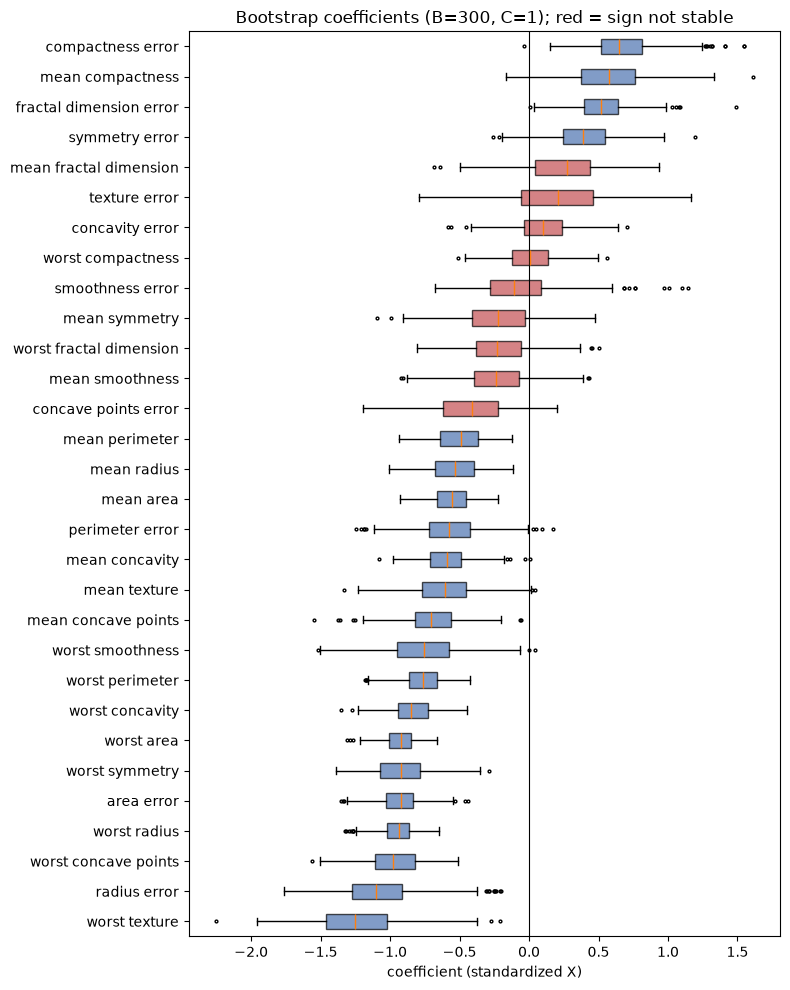

,C=0.01,C=0.1,C=1,C=10,C=100
mean compactness,-0.098,-0.002,0.648,3.480,11.466
compactness error,0.021,0.227,0.647,0.205,-2.340
worst compactness,-0.138,-0.151,0.056,0.412,1.135
concavity error,0.024,0.079,0.161,1.680,7.715
worst texture,-0.214,-0.564,-1.255,-2.411,-3.182
worst concave points,-0.240,-0.508,-0.954,-1.305,-0.450
mean radius,-0.212,-0.397,-0.511,-0.176,1.138


In [22]:
from sklearn.base import clone

# 一般精度的 pipeline 就夠了（tol 預設），300 次 fit 約數秒
boot_pipe = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=10000))

B = 300
rng = np.random.default_rng(42)
n = len(X_train)
boot_coef = np.empty((B, len(feature_names)))
for i in range(B):
    idx = rng.integers(0, n, size=n)  # 有放回抽樣：n 個 0..n-1 的隨機整數，可重複
    m = clone(boot_pipe).fit(X_train.iloc[idx], y_train.iloc[idx])  # scaler 也在每個 bootstrap 樣本上重新 fit
    boot_coef[i] = m[-1].coef_[0]

boot = pd.DataFrame({
    "coef": sk_lr.coef_[0],  # 完整訓練集 fit 的係數
    "boot_median": np.median(boot_coef, axis=0),
    "ci_low": np.percentile(boot_coef, 2.5, axis=0),
    "ci_high": np.percentile(boot_coef, 97.5, axis=0),
    "P(coef>0)": (boot_coef > 0).mean(axis=0),
    "corr_with_label": interp["corr_with_label"].reindex(feature_names).to_numpy(),
    "sign_flip": interp["sign_flip"].reindex(feature_names).to_numpy(),
}, index=feature_names)
boot["sign_stable"] = (boot["P(coef>0)"] >= 0.95) | (boot["P(coef>0)"] <= 0.05)
boot = boot.sort_values("boot_median")
display(boot.round(3))
print(f"正負號穩定的特徵：{boot['sign_stable'].sum()} / {len(boot)}")
print("翻號（係數與相關係數反向）的 8 個特徵中，正負號穩定的：",
      boot.index[boot["sign_flip"] & boot["sign_stable"]].tolist())

# 箱形圖：每個特徵 300 個 bootstrap 係數的分布；紅色 = 正負號不穩定（95% 區間跨過 0）
order = boot.index.tolist()
fig, ax = plt.subplots(figsize=(8, 10))
bp = ax.boxplot([boot_coef[:, feature_names.index(f)] for f in order], orientation="horizontal",
                tick_labels=order, patch_artist=True, flierprops={"markersize": 2})
for patch, f in zip(bp["boxes"], order):
    patch.set_facecolor("#4C72B0" if boot.loc[f, "sign_stable"] else "#C44E52")
    patch.set_alpha(0.7)
ax.axvline(0, color="k", lw=0.8)
ax.set_title(f"Bootstrap coefficients (B={B}, C=1); red = sign not stable")
ax.set_xlabel("coefficient (standardized X)")
fig.tight_layout()
plt.show()

# 同一批特徵在不同正則化強度下的係數（完整訓練集）
watch = ["mean compactness", "compactness error", "worst compactness", "concavity error",
         "worst texture", "worst concave points", "mean radius"]
c_path = pd.DataFrame({
    f"C={C}": clone(boot_pipe).set_params(logisticregression__C=C).fit(X_train, y_train)[-1].coef_[0]
    for C in [0.01, 0.1, 1, 10, 100]
}, index=feature_names)
display(c_path.loc[watch].round(3))

#### 讀法（以本次結果為例：21 / 30 個特徵正負號穩定）

- **方向可信**：worst texture、worst concave points，300 次重抽樣全部為負，C = 0.01～100 下也都是負的。
- **正負號由抽樣決定**：worst compactness、concavity error、smoothness error 等 9 個，區間跨過 0，不能解讀方向。
- **抽樣下穩定、卻隨 C 改變**：mean radius 在 C ≤ 10 為負、C = 100 翻成 +1.14；compactness error 在 C = 100 翻成 −2.34；mean compactness 從 C = 0.1 的 ≈ 0 一路放大到 C = 100 的 11.5。
  → 正則化越弱，共線特徵之間「一正一負互相抵銷」越嚴重（第二章 Ridge 係數路徑的反方向）。
- **翻號的 8 個特徵中有 4 個正負號穩定**（mean compactness、compactness error、symmetry error、fractal dimension error）：它們在「其他特徵固定」下的條件效果方向確實與單變量相關相反（典型的抑制變數 suppressor），但這仍是條件效果 —— 單獨看 mean compactness，越大越可能惡性（相關 −0.61），兩者並不矛盾。

**結論**：bootstrap 告訴我們哪些係數「對抽樣穩定」，C 掃描告訴我們哪些係數「對模型設定穩定」；兩者都穩定、又不在強共線組裡的係數，才比較適合解讀方向。

---
## 5. 調參

全程只用 `X_train`（測試集鎖住），依 README「調參流程」：

| 類別 | 超參數 | 說明 |
| --- | --- | --- |
| 正則化 | `C` | 正則化強度的倒數（C 小 = 懲罰強 = 模型簡單）。尺度型 → log 尺度搜尋 |
| 正則化 | `l1_ratio` | 0 = L2、1 = L1、之間 = Elastic Net（sklearn 1.8 起取代舊的 `penalty`） |
| 最佳化 | `solver`、`max_iter`、`tol` | 只影響「解得多快、多準」，不改變最佳解，不需要調 |
| 決策 | 分類門檻 | 不是訓練參數，是 fit 完之後的決策規則；一樣只能用 CV 決定 |

**選模型的指標用 log loss**（`neg_log_loss`）；accuracy 一起列出來參考。

In [23]:
from sklearn.model_selection import GridSearchCV, learning_curve, validation_curve

base_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
baseline.loc["LogReg default (C=1)"] = cv_summary(base_pipe)
display(baseline)

,log_loss,accuracy,roc_auc
Dummy most_frequent,13.4669 ± 0.0000,0.6264 ± 0.0000,0.5000 ± 0.0000
Dummy prior,0.6609 ± 0.0000,0.6264 ± 0.0000,0.5000 ± 0.0000
LogReg default (C=1),0.0723 ± 0.0289,0.9780 ± 0.0098,0.9959 ± 0.0050


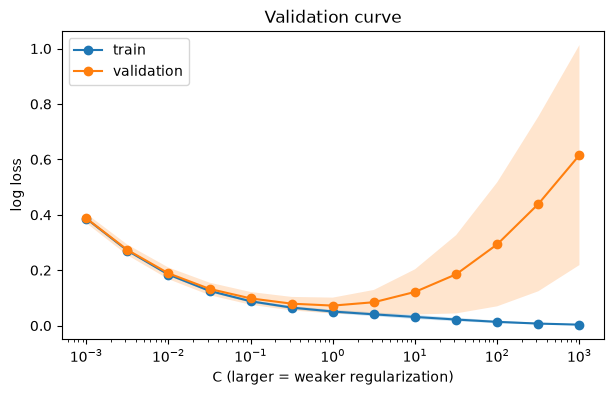

,C,train,val,val_std
0,0.0010,0.3864,0.3873,0.0171
1,0.0032,0.2710,0.2734,0.0191
2,0.0100,0.1843,0.1888,0.0210
3,0.0316,0.1254,0.1326,0.0225
4,0.1000,0.0879,0.0983,0.0230
5,0.3162,0.0650,0.0793,0.0244
6,1.0000,0.0509,0.0723,0.0289
7,3.1623,0.0407,0.0846,0.0444
8,10.0000,0.0314,0.1218,0.0816
9,31.6228,0.0220,0.1854,0.1413


In [24]:
# 單一參數掃描：C
Cs = np.logspace(-3, 3, 13)
tr_scores, va_scores = validation_curve(
    base_pipe,
    X_train,
    y_train,
    param_name="logisticregression__C",
    param_range=Cs,
    cv=cv,
    scoring="neg_log_loss",
)
tr_loss, va_loss = -tr_scores, -va_scores  # 轉回 log loss（越低越好）

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in [("train", tr_loss), ("validation", va_loss)]:
    ax.plot(Cs, s.mean(1), "o-", label=name)
    ax.fill_between(Cs, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
ax.set_xscale("log")
ax.set_xlabel("C (larger = weaker regularization)")
ax.set_ylabel("log loss")
ax.set_title("Validation curve")
ax.legend()
plt.show()
display(
    pd.DataFrame(
        {
            "C": Cs,
            "train": tr_loss.mean(1),
            "val": va_loss.mean(1),
            "val_std": va_loss.std(1),
        }
    ).round(4)
)

### TODO 15（問答）

> **(1)** 哪一段 C 是欠擬合、哪一段是過擬合？各自的判斷依據是什麼（train 與 val 曲線的關係）？

validation log loss 在 C = 1 最低（0.072），以此為分界：

| 區段 | train vs val | 解讀 | 判斷依據 |
| --- | --- | --- | --- |
| 欠擬合（C ≲ 0.03） | 都高（C = 0.001 時 0.386 vs 0.387），幾乎重疊、差距 < 0.01 | 模型被懲罰壓得太小（$\lVert w \rVert$ 小 → 機率都擠在 0.5 附近），連訓練集都學不好 → 高偏差（bias） | train loss 本身就高，而且 val ≈ train |
| 過渡區（0.1 ≲ C ≲ 1） | 一起下降、差距開始拉開（C = 1 時 0.051 vs 0.072） | val 到達最低點 | — |
| 過擬合（C ≳ 3） | train 繼續下降（C = 1000 時 0.0035），val 反轉上升（0.62，比 Dummy prior 的 0.66 只好一點） | 模型開始擬合訓練集特有的細節（TODO 8：資料線性可分，C 越大越接近無正則化的「把 $w$ 放大」），學到的東西無法推廣到沒看過的資料 → 高變異（variance） | train 與 val 的差距持續擴大（0.001 → 0.02 → 0.61），而且 val 往上走 |

- 注意：邏輯回歸的模型形式（線性邊界）固定不變，C 控制的是「有效容量」—— 允許 $\|w\|$ 多大、機率可以多極端。
- 另外，C = 0.316（0.079）與最佳差距小於一個標準差（0.029），統計上分不出優劣 → TODO 16 的 1-SE rule。

> **(2)** 為什麼 train log loss 隨 C 單調下降？C 很大時 val 的標準差為什麼也跟著變大？（連結 TODO 8）

**train 單調下降**：目標函數是 $\text{CE}(w) + \frac{\lambda}{2}\|w\|^2$，$\lambda = 1/(Cn)$。C 越大 → $\lambda$ 越小 → 模型越能「花」$\|w\|$ 去降低訓練 CE。可以嚴格證明：設 $\lambda_1 > \lambda_2$ 的最佳解分別為 $w_1$、$w_2$，$R = \frac{1}{2}\|w\|^2$，由兩者各自的最佳性

$$\text{CE}_2 + \lambda_2 R_2 \le \text{CE}_1 + \lambda_2 R_1, \qquad \text{CE}_1 + \lambda_1 R_1 \le \text{CE}_2 + \lambda_1 R_2$$

相加得 $(\lambda_1 - \lambda_2)(R_1 - R_2) \le 0$ → $R_1 \le R_2$，代回第一式 → $\text{CE}_2 \le \text{CE}_1$。也就是 C 越大，$\|w\|$ 不會變小、訓練 CE 不會變大。資料又線性可分，$C \to \infty$ 時訓練 CE → 0（TODO 8）。

**val 標準差變大**：不只是「係數不穩定」，關鍵在 log loss 對「有把握地錯」沒有上限：

- C 大 → $\|w\|$ 大（C = 1 約 3.4，C = 1000 約 38–64）→ $|z|$ 大 → 機率被推到接近 0 或 1。
- 一旦預測錯，單筆 loss $\approx |z|$（$\log(1 + e^z) \approx z$）：C = 1000 時單筆最大 loss 11–49，C = 1 時只有 1–6。
- 每個 fold 的 log loss 被少數幾筆錯得離譜的樣本主導：C = 1000 時最錯的 3 筆佔該 fold 總 loss 的 81–97%。
- 這幾筆落在哪個 fold、錯得多離譜，取決於切分 → fold 間 log loss 從 0.25 到 1.32，標準差隨之暴增。
- （而 accuracy 在 fold 間只從 0.92 到 0.97，因為它不看信心程度 —— 又是 TODO 2 的教訓。）

係數不穩定也有貢獻：不同 fold 訓練出的 $\|w\|$ 差很多（38 vs 64），等於每個 fold 的模型「自信程度」都不同。

best_params_： {'logisticregression__C': np.float64(1.0), 'logisticregression__l1_ratio': 0.0}   CV log loss： 0.0706


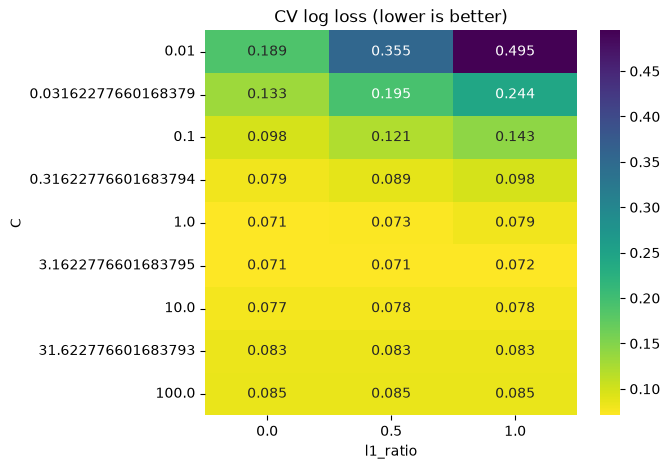

In [25]:
# 2D 搜尋：C × l1_ratio（saga 是 sklearn 唯一支援 Elastic Net 的 solver）
param_grid = {
    "logisticregression__C": np.logspace(-2, 2, 9),
    "logisticregression__l1_ratio": [0.0, 0.5, 1.0],
}
search_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="saga", tol=1e-3, max_iter=10000, random_state=42),
)
gs = GridSearchCV(search_pipe, param_grid, cv=cv, scoring="neg_log_loss", n_jobs=-1)
gs.fit(X_train, y_train)

res = pd.DataFrame(
    {
        "C": gs.cv_results_["param_logisticregression__C"].astype(float),
        "l1_ratio": gs.cv_results_["param_logisticregression__l1_ratio"].astype(float),
        "mean": -gs.cv_results_["mean_test_score"],  # log loss，越低越好
        "std": gs.cv_results_["std_test_score"],
    }
)
print("best_params_：", gs.best_params_, "  CV log loss：", round(-gs.best_score_, 4))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    res.pivot(index="C", columns="l1_ratio", values="mean"),
    annot=True,
    fmt=".3f",
    cmap="viridis_r",
    ax=ax,
)
ax.set_title("CV log loss (lower is better)")
plt.show()

In [26]:
# one-standard-error rule：在「跟最佳差距不到一個標準差」的候選中，挑最簡單的
best = res.loc[res["mean"].idxmin()]

# TODO 16（程式）
#   - ok：mean ≤ best.mean + best.std 的所有列
#   - choice：ok 裡面最簡單的一列 ——「C 最小」（正則化最強）；C 一樣時取 l1_ratio 較大的（較稀疏）
#   - 提示：DataFrame.sort_values([...], ascending=[...]).iloc[0]
ok = res[res["mean"] <= best["mean"] + best["std"]]
choice = ok.sort_values(by=["C", "l1_ratio"], ascending=[True, False]).iloc[0]

print("CV 最佳 ：", best.round(4).to_dict())
print("1-SE 選擇：", choice.round(4).to_dict())
print("✅ 1-SE 應選到 C ≈ 0.316、l1_ratio = 0.5")

from sklearn.base import clone

model_1se = (
    clone(search_pipe)
    .set_params(
        logisticregression__C=choice["C"],
        logisticregression__l1_ratio=choice["l1_ratio"],
    )
    .fit(X_train, y_train)
)
print("best 模型非零係數：", (gs.best_estimator_[-1].coef_ != 0).sum(), "/ 30")
print("1-SE 模型非零係數：", (model_1se[-1].coef_ != 0).sum(), "/ 30")

CV 最佳 ： {'C': 1.0, 'l1_ratio': 0.0, 'mean': 0.0706, 'std': 0.0269}
1-SE 選擇： {'C': 0.3162, 'l1_ratio': 0.5, 'mean': 0.0888, 'std': 0.0202}
✅ 1-SE 應選到 C ≈ 0.316、l1_ratio = 0.5
best 模型非零係數： 30 / 30
1-SE 模型非零係數： 23 / 30


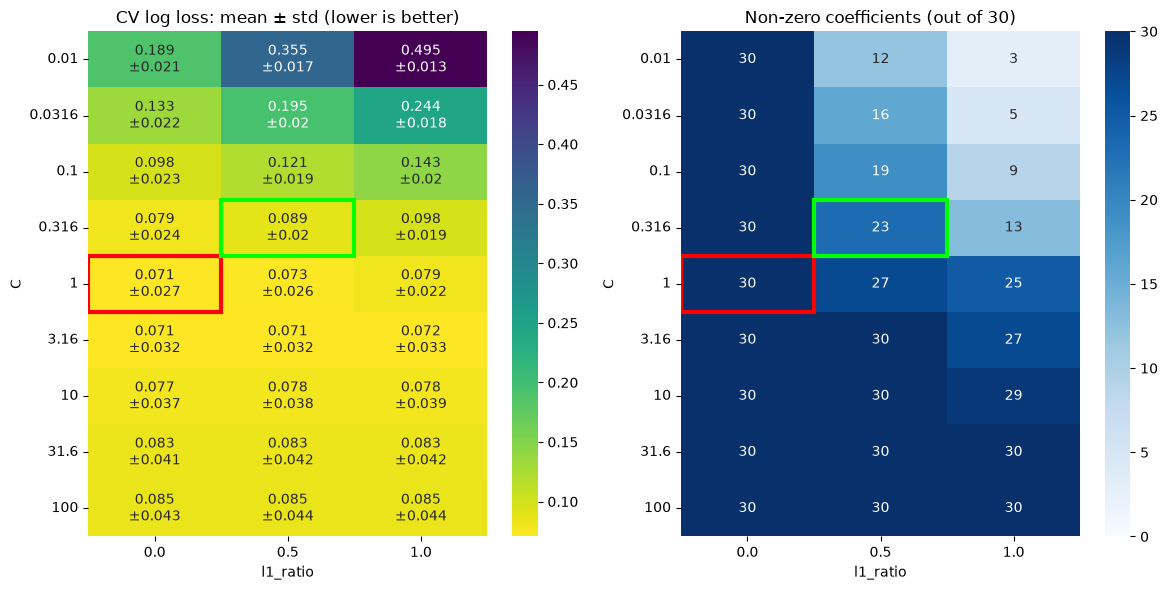

1-SE 門檻：mean ≤ 0.0706 + 0.0269 = 0.0975


In [27]:
# TODO 17 (2) 用的圖：同一組 C × l1_ratio，左邊是 CV log loss（mean ± std），右邊是「在完整訓練集 fit 後的非零係數數量」
nonzero = res.copy()
nonzero["n_nonzero"] = [
    int(
        (
            clone(search_pipe)
            .set_params(
                logisticregression__C=r.C, logisticregression__l1_ratio=r.l1_ratio
            )
            .fit(X_train, y_train)[-1]
            .coef_
            != 0
        ).sum()
    )
    for r in res.itertuples()
]

mean_tbl = res.pivot(index="C", columns="l1_ratio", values="mean")
std_tbl = res.pivot(index="C", columns="l1_ratio", values="std")
annot = mean_tbl.round(3).astype(str) + "\n±" + std_tbl.round(3).astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.heatmap(mean_tbl, annot=annot, fmt="", cmap="viridis_r", ax=axes[0])
axes[0].set_title("CV log loss: mean ± std (lower is better)")
sns.heatmap(
    nonzero.pivot(index="C", columns="l1_ratio", values="n_nonzero"),
    annot=True,
    fmt="d",
    cmap="Blues",
    vmin=0,
    vmax=30,
    ax=axes[1],
)
axes[1].set_title("Non-zero coefficients (out of 30)")
for ax in axes:  # 框出 CV 最佳（紅）與 1-SE 選擇（綠）
    for r, color in [(best, "red"), (choice, "lime")]:
        i = list(mean_tbl.index).index(r["C"])
        j = list(mean_tbl.columns).index(r["l1_ratio"])
        ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor=color, lw=3))
    ax.set_yticklabels([f"{c:.3g}" for c in mean_tbl.index], rotation=0)
fig.tight_layout()
plt.show()
print(
    f"1-SE 門檻：mean ≤ {best['mean']:.4f} + {best['std']:.4f} = {best['mean'] + best['std']:.4f}"
)

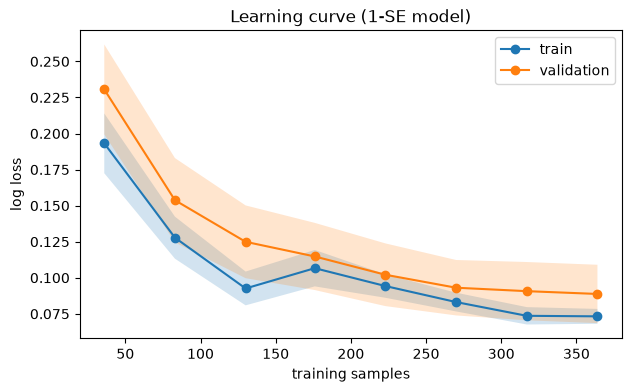

In [28]:
# 學習曲線：再多一點資料會更好嗎？
sizes, tr_s, va_s = learning_curve(
    model_1se,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_log_loss",
    train_sizes=np.linspace(0.1, 1.0, 8),
)
fig, ax = plt.subplots(figsize=(7, 4))
for name, s in [("train", -tr_s), ("validation", -va_s)]:
    ax.plot(sizes, s.mean(1), "o-", label=name)
    ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
ax.set_xlabel("training samples")
ax.set_ylabel("log loss")
ax.set_title("Learning curve (1-SE model)")
ax.legend()
plt.show()

### TODO 17（問答）

> **(1)** 為什麼選模型用 log loss，而不是 accuracy？
>
> 提示：每個 validation fold 約 91 筆，accuracy 的最小變化單位是多少？accuracy 在不在乎模型「多有把握」？

- **解析度太粗**：每個 fold 約 91 筆，accuracy 只能以 1/91 ≈ 1.1% 為單位跳動；整體只有 0～3 筆錯，候選模型的 accuracy 大量平手。實測 CV 最佳（C=1, L2）與 1-SE 模型（C=0.316, l1_ratio=0.5）的 CV accuracy 都是 0.978，完全分不出來；log loss 則是 0.071 vs 0.089。
- **不看信心**：accuracy 只看機率落在門檻的哪一側，$P = 0.51$ 與 $P = 0.99$ 判對的得分一樣，$P = 0.49$ 與 $P = 0.01$ 判錯也一樣。log loss 是連續的，每一筆機率的微小改善都會反映出來，validation curve 才畫得出平滑、可判讀的形狀。
- **proper scoring rule**：log loss 只有在預測機率等於真實機率時期望值最小，鼓勵模型給出「誠實」的機率；它也正是訓練時最小化的目標，訓練與選模型用同一把尺。

注意：選模型用 log loss，不代表最後只報 log loss —— 實際決策關心的指標（例如惡性 recall）要另外看（下一格的門檻）。

> **(2)** 從上一格的兩張 heatmap 看，L1（l1_ratio=1）和 L2 在 C 小的時候差在哪？1-SE 選的模型用了幾個特徵？這樣的取捨合理嗎？

C 小（正則化強）時：

- **特徵數**：L2 永遠保留全部 30 個（只縮小、不歸零）；L1 大量歸零（C = 0.01 只剩 3 個、C = 0.1 剩 9 個）。
- **log loss**：L1 明顯「較差」（較高）—— C = 0.01 時 0.495 vs 0.189、C = 0.1 時 0.143 vs 0.098。L1 在強懲罰下只能靠少數特徵預測，資訊損失大 → 欠擬合更嚴重；L2 把懲罰分攤給全部特徵，共線的一組特徵可以「合力」保留資訊（TODO 14），所以同樣的 C 下表現較好。
- C 變大後兩者差距消失（C ≥ 3 時幾乎相同），因為懲罰弱到不影響結果，L1 也不再歸零。

**1-SE 選的模型**：C = 0.316、l1_ratio = 0.5，用了 23 / 30 個特徵；CV log loss 0.089 ± 0.020，與最佳的 0.071 差距小於一個標準差（0.027），accuracy 相同（0.978）。

**取捨是否合理**：在統計上分不出優劣的前提下，選特徵較少、正則化較強的模型，可降低過擬合風險、較容易解讀（one-standard-error rule 的精神），所以合理。但有幾點限制：

- 這份資料的 30 個特徵都是從同一張影像算出來的，少 7 個並不省任何量測成本，稀疏的好處主要只在可解讀性。
- 共線特徵之間 L1 選誰不穩定（bootstrap 那格的教訓）：被砍掉的特徵不代表「沒用」，通常只是它的資訊已由相關的特徵提供。如果領域知識認為某個被砍掉的特徵很重要，兩者並不矛盾。
- 1-SE rule 本身是經驗法則；如果目標是最準的機率，選 CV 最佳也完全合理。

> **(3)** 學習曲線的兩條線最後的距離與趨勢，代表下一步該加資料、加模型複雜度，還是都不太需要？

實測（log loss）：

| n | 36 | 130 | 364 |
| --- | --- | --- | --- |
| train | 0.193 | 0.093 | 0.073 |
| val | 0.231 | 0.125 | 0.089 |

- val 在 130 筆後並沒有停止改善：130 → 364 筆又下降約 29%；只是最後兩點（317 → 364）只降 0.002，已趨近平穩。
- train 在 176 筆時的小反彈（0.093 → 0.107）是雜訊，之後又持續下降。
- 本例 train loss 隨 $n$ 下降，與一般「資料越多越難擬合、train loss 上升」相反：sklearn 的目標函數是 $C \cdot \sum \text{CE} + \frac{1}{2}\|w\|^2$，$n$ 越大，CE 的加總越大、懲罰相對越弱（等效 $\lambda = 1/(Cn)$ 變小），所以小樣本時被壓得更兇、欠擬合更嚴重。
- `learning_curve` 是從每個 fold 的訓練資料中「取前 $n$ 筆」（不放回、沒有重複資料），每一點都是不同大小的子集。

判讀：

- 最後 gap = 0.016，小於 val 的標準差（0.020）→ 沒有明顯過擬合（高變異）。
- val 已接近平穩、train 本身也不高 → 沒有明顯欠擬合；第 5 節 C 的掃描也顯示放寬正則化（增加有效容量）只會更差。

→ 加資料只會帶來小幅改善，加模型複雜度不太需要。剩下的錯誤多半來自兩類在特徵空間的重疊（EDA 的散點圖），要再進步比較可能靠新的資訊（新特徵、更好的量測），而不是更多同類資料或更複雜的模型。

✅ t_star = 0.83（應為 0.83）  OOF 惡性 recall = 0.982  precision = 0.874


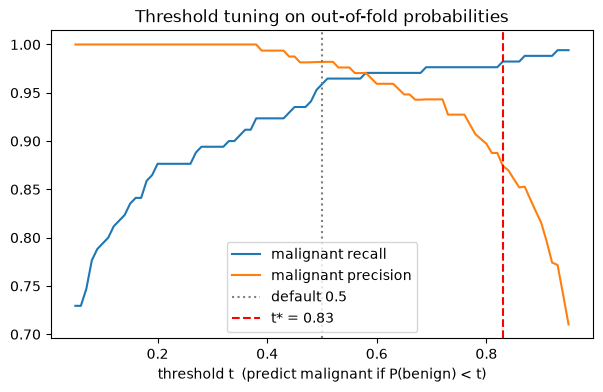

In [29]:
# 分類門檻：預設 P(benign) ≥ 0.5 判良性。漏掉惡性（判成良性）的代價遠高於誤判良性為惡性。
# 用 out-of-fold（OOF）機率選門檻：每筆訓練資料的機率都來自「沒看過它」的模型
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    model_1se, X_train, y_train, cv=cv, method="predict_proba"
)[
    :, 1
]  # P(benign)
is_mal = y_train.to_numpy() == 0
ts = np.round(np.linspace(0.05, 0.95, 91), 2)
recall_mal = np.array([((oof_prob < t) & is_mal).sum() / is_mal.sum() for t in ts])
precision_mal = np.array(
    [((oof_prob < t) & is_mal).sum() / max((oof_prob < t).sum(), 1) for t in ts]
)

TARGET_RECALL = 0.98
# TODO 18（程式）：找出讓惡性 recall ≥ TARGET_RECALL 的「最小」門檻 t_star（一行）
#   - 判斷規則：P(benign) < t 判惡性，所以 t 越大，判成惡性的越多
#   - 提示：np.argmax 遇到布林陣列會回傳第一個 True 的位置
t_star = ts[np.argmax(recall_mal >= TARGET_RECALL)]
print(
    f"✅ t_star = {t_star}（應為 0.83）  OOF 惡性 recall = {recall_mal[ts == t_star][0]:.3f}  "
    f"precision = {precision_mal[ts == t_star][0]:.3f}"
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ts, recall_mal, label="malignant recall")
ax.plot(ts, precision_mal, label="malignant precision")
ax.axvline(0.5, color="gray", ls=":", label="default 0.5")
ax.axvline(t_star, color="r", ls="--", label=f"t* = {t_star}")
ax.set_xlabel("threshold t  (predict malignant if P(benign) < t)")
ax.set_title("Threshold tuning on out-of-fold probabilities")
ax.legend()
plt.show()

### TODO 19（問答）

> **(1)** 為什麼門檻要用 OOF 機率選，而不能用 model_1se 在訓練集上的機率？更不能用測試集？

原則：用來「做決定」的資料，不能是模型「看過」的資料（README 資料切分原則）。

- **訓練集機率（in-sample）偏樂觀**：model_1se 就是用這 455 筆 fit 的，對它們的機率比對新資料更有把握、更正確。實測：in-sample 只有 4 個惡性被給 $P(\text{benign}) \ge 0.5$，選出 $t^* = 0.67$；OOF 有 7 個，選出 $t^* = 0.83$。用 in-sample 會高估模型能力 → 選出太寬鬆的門檻 → 到新資料上惡性 recall 達不到 98%。
- **OOF（out-of-fold）機率**：`cross_val_predict` 讓每一筆的機率都來自「訓練時沒看過它」的模型（5 個 fold 各自 fit），模擬「模型面對新病人」的表現，所以能拿來做決定；而且 455 筆都用上，比另外切一塊驗證集更省資料。（小細節：OOF 的 5 個模型各只用 4/5 的資料訓練，略差於用全部資料的 model_1se → OOF 估計稍微保守，方向是安全的。）
- **測試集**：一旦依測試集分數選門檻，門檻就被「調到剛好適合這 114 筆」，測試集分數不再是公正的推廣能力估計（偏樂觀）。測試集只能在所有決定都做完後評估一次。

誠實的補充：本次測試集上 $t = 0.67$ 與 $0.83$ 的惡性 recall 都是 0.976（42 筆惡性錯 1 筆）。測試集太小（1 筆 = 2.4%），分辨不出兩者差異；原則仍成立，只是這份資料的規模無法驗證。

> **(2)** 調門檻和 `class_weight="balanced"` 都能提高惡性 recall，兩者作用在哪個階段？哪個會改變 $w$？

- **調門檻**：作用在「訓練之後」的決策規則。$w$、$b$、預測機率完全不變，只改「$P(\text{benign})$ 多少以上判良性」。不需重新訓練，換目標（例如 recall 改成 0.95）只要改一個數字。
- **`class_weight="balanced"`**：作用在「訓練當中」的 loss —— 每類樣本的 loss 乘上 $\frac{n}{K \cdot n_k}$：惡性 $455 / (2 \times 170) = 1.34$、良性 $455 / (2 \times 285) = 0.80$，惡性錯一筆的代價變大 → 會改變 $w$ 與 $b$，需要重新訓練。實測主要改變的是 bias（0.40 → 0.04），係數最多只變 0.056；OOF 惡性 recall（門檻 0.5）0.959 → 0.971。

兩者為何效果相似：對邏輯回歸，加權大致等於把 bias 平移約 $\log(\text{權重比}) = \log(1.34 / 0.80) \approx 0.52$（實測 0.36，差異來自正則化），而平移 bias 又等同於換一個門檻。

差別：

- 加權後的機率不再反映真實的發生比例（被刻意往惡性偏），校準變差；調門檻保留原本校準好的機率。
- 加權在非線性模型（例如樹模型）中會改變決策邊界的「形狀」，效果不只是平移，那時才是調門檻做不到的事。

→ 對邏輯回歸，先訓練出好的機率、再依成本選門檻，通常是較乾淨的做法。

---
## 6. 測試集評估

模型與門檻都已經用 CV 決定好，測試集只評估一次。
`classification_metrics` 的 precision／recall／f1 以**良性（1）為正類**；另外加記惡性 recall。

,accuracy,precision,recall,f1,roc_auc,recall_malignant
Dummy prior,0.6316,0.6316,1.0000,0.7742,0.5000,0.0000
LogReg GD (scratch),0.9825,0.9861,0.9861,0.9861,0.9954,0.9762
LogReg Newton (scratch),0.9825,0.9861,0.9861,0.9861,0.9954,0.9762
LogisticRegression C=1 (sklearn),0.9825,0.9861,0.9861,0.9861,0.9954,0.9762
LogReg CV-best (sklearn),0.9825,0.9861,0.9861,0.9861,0.9960,0.9762
LogReg 1-SE (sklearn),0.9825,0.9861,0.9861,0.9861,0.9957,0.9762
LogReg 1-SE + threshold (sklearn),0.8947,0.9839,0.8472,0.9104,0.9957,0.9762


,model,roc_auc,time,accuracy,precision,recall,f1,recall_malignant,params,notes
0,LogReg CV-best (sklearn),0.9960,2026-10-23 23:53,0.9825,0.9861,0.9861,0.9861,0.9762,"{""C"": 1.0, ""l1_ratio"": 0.0}",NaN
1,LogReg 1-SE (sklearn),0.9957,2026-10-23 23:53,0.9825,0.9861,0.9861,0.9861,0.9762,"{""C"": 0.31622776601683794, ""l1_ratio"": 0.5}",NaN
2,LogReg 1-SE + threshold (sklearn),0.9957,2026-10-23 23:53,0.8947,0.9839,0.8472,0.9104,0.9762,"{""C"": 0.31622776601683794, ""l1_ratio"": 0.5, ""t...",NaN
3,LogReg GD (scratch),0.9954,2026-10-23 23:53,0.9825,0.9861,0.9861,0.9861,0.9762,"{""C"": 1.0, ""lr"": 1.0, ""epochs"": 5050}",NaN
4,LogReg Newton (scratch),0.9954,2026-10-23 23:53,0.9825,0.9861,0.9861,0.9861,0.9762,"{""C"": 1.0, ""iters"": 10}",NaN
5,LogisticRegression C=1 (sklearn),0.9954,2026-10-23 23:53,0.9825,0.9861,0.9861,0.9861,0.9762,"{""C"": 1.0}",NaN
6,Dummy prior,0.5000,2026-10-23 23:53,0.6316,0.6316,1.0000,0.7742,0.0000,NaN,NaN


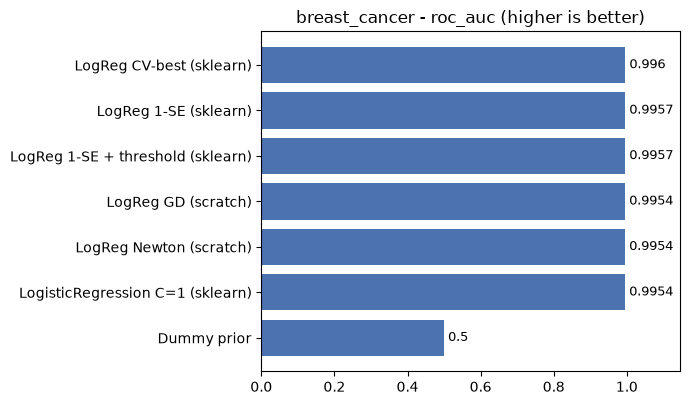

In [30]:
from ml_dl_llm.results import compare, log_result

BENCH = "breast_cancer"
y_te = y_test.to_numpy()


def evaluate(prob_benign: np.ndarray, t: float = 0.5) -> dict[str, float]:
    """prob_benign (n,) 是 P(benign)，≥ t 判良性。回傳 classification_metrics 的指標，再加上 recall_malignant。"""
    pred = (prob_benign >= t).astype(int)
    m = classification_metrics(y_te, pred, prob_benign)
    m["recall_malignant"] = round(
        float(((pred == 0) & (y_te == 0)).sum() / (y_te == 0).sum()), 4
    )
    return m


dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
c1, l1 = float(choice["C"]), float(choice["l1_ratio"])
bp = {k.split("__")[1]: float(v) for k, v in gs.best_params_.items()}

# 名稱: (P(benign), 門檻, 要記下的參數)
eval_models = {
    "Dummy prior": (dummy.predict_proba(X_test)[:, 1], 0.5, {}),
    "LogReg GD (scratch)": (
        gd.predict_proba(X_test_s)[:, 1],
        0.5,
        {"C": gd.C, "lr": gd.lr, "epochs": len(gd.loss_history_)},
    ),
    "LogReg Newton (scratch)": (
        newton.predict_proba(X_test_s)[:, 1],
        0.5,
        {"C": newton.C, "iters": len(newton.grad_norm_history_)},
    ),
    "LogisticRegression C=1 (sklearn)": (
        sk_pipe.predict_proba(X_test)[:, 1],
        0.5,
        {"C": 1.0},
    ),
    "LogReg CV-best (sklearn)": (
        gs.best_estimator_.predict_proba(X_test)[:, 1],
        0.5,
        bp,
    ),
    "LogReg 1-SE (sklearn)": (
        model_1se.predict_proba(X_test)[:, 1],
        0.5,
        {"C": c1, "l1_ratio": l1},
    ),
    "LogReg 1-SE + threshold (sklearn)": (
        model_1se.predict_proba(X_test)[:, 1],
        t_star,
        {"C": c1, "l1_ratio": l1, "threshold": float(t_star)},
    ),
}

test_scores = {}
for name, (prob, t, params) in eval_models.items():
    metrics = evaluate(prob, t)
    test_scores[name] = metrics
    log_result(BENCH, name, metrics, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "roc_auc")

---
## 7. 診斷

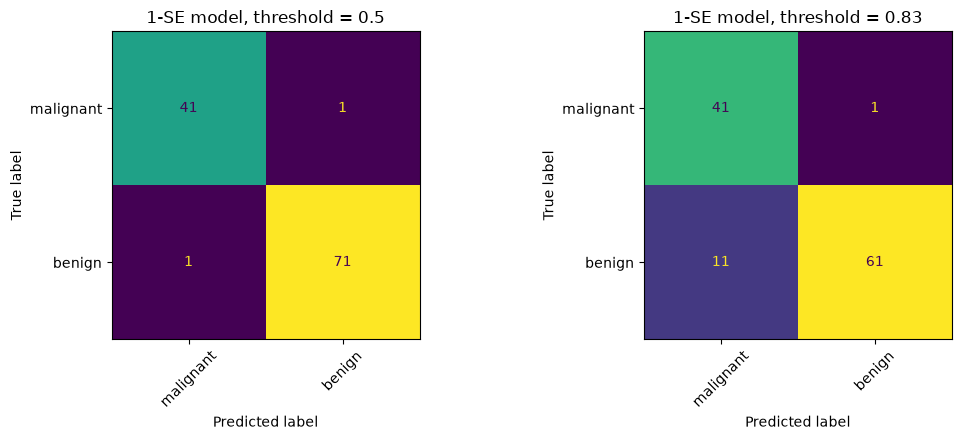

錯誤樣本（門檻 0.5；特徵是標準化後的值，單位 = 標準差）：


,true,P(benign),worst concave points,worst perimeter,mean concave points,worst radius,mean perimeter,worst area
541,1,0.374,0.10,0.21,-0.24,0.01,0.18,-0.11
73,0,0.834,0.37,0.11,0.06,0.08,-0.05,-0.10


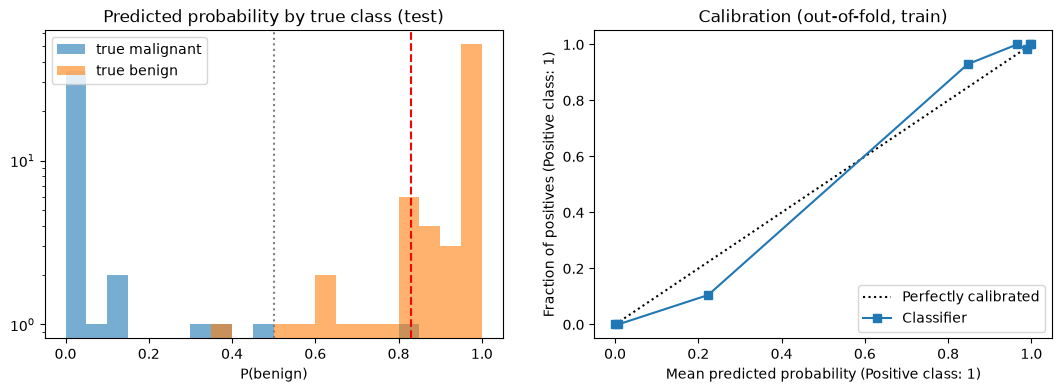

In [31]:
from sklearn.calibration import CalibrationDisplay
from ml_dl_llm.metrics import plot_confusion_matrix

prob_te = model_1se.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, t_star]):
    plot_confusion_matrix(
        y_te, (prob_te >= t).astype(int), labels=["malignant", "benign"], ax=ax
    )
    ax.set_title(f"1-SE model, threshold = {t}")
fig.tight_layout()
plt.show()

# 錯誤樣本：機率多少？是「差一點」還是「很有把握地錯」？
z_te = pd.DataFrame(
    model_1se[0].transform(X_test), columns=feature_names, index=X_test.index
)
wrong = (prob_te >= 0.5).astype(int) != y_te
err = z_te.loc[wrong, list(top6)].round(2)
err.insert(0, "P(benign)", prob_te[wrong].round(3))
err.insert(0, "true", y_te[wrong])
print("錯誤樣本（門檻 0.5；特徵是標準化後的值，單位 = 標準差）：")
display(err)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, name in [(0, "malignant"), (1, "benign")]:
    axes[0].hist(
        prob_te[y_te == k], bins=20, range=(0, 1), alpha=0.6, label=f"true {name}"
    )
axes[0].axvline(0.5, color="gray", ls=":")
axes[0].axvline(t_star, color="r", ls="--")
axes[0].set_yscale("log")
axes[0].set_xlabel("P(benign)")
axes[0].set_title("Predicted probability by true class (test)")
axes[0].legend()

CalibrationDisplay.from_predictions(
    y_train, oof_prob, n_bins=8, strategy="quantile", ax=axes[1]
)
axes[1].set_title("Calibration (out-of-fold, train)")
plt.show()

### TODO 20（問答）本章總結

> **(1)** 門檻 0.5 → t_star，測試集的混淆矩陣怎麼變？付出了什麼代價？測試集上的惡性 recall 有達到 CV 時設定的目標（0.98）嗎？為什麼？（看第 6 節成績表的 recall_malignant）

混淆矩陣（列 = 真實、欄 = 預測）：

| 門檻 | 真惡性 → 判惡性 | 真惡性 → 判良性 | 真良性 → 判惡性 | 真良性 → 判良性 | 錯誤 | accuracy |
| --- | --- | --- | --- | --- | --- | --- |
| 0.5 | 41 | 1 | 1 | 71 | 2 筆 | 0.982 |
| 0.83 | 41 | 1 | 11 | 61 | 12 筆 | 0.895 |

- 多了 10 個良性被判成惡性（偽陽性 1 → 11），惡性的 precision 從 0.976 降到 0.788。這是刻意的保守取捨：漏掉惡性（偽陰性）的代價遠高於讓良性病人多做一次檢查。
- 但漏掉的惡性仍是 1 筆，惡性 recall 停在 0.976（41 / 42），沒有改善，也沒達到 0.98：唯一漏掉的惡性（樣本 73）$P(\text{benign}) = 0.8345$，剛好在 0.83 之上，要門檻 ≥ 0.84 才抓得到。→ 這次的代價（10 個偽陽性）完全沒換到收益。
- 為什麼沒達標：測試集只有 42 個惡性，recall 只能取 40/42 = 0.952、41/42 = 0.976、42/42 = 1.0 這幾個值，根本不可能「剛好 0.98」；OOF 選出的門檻是對 170 個惡性的平均保證，用在 42 筆上，差 1 筆就是 2.4% 的跳動。0.98 是在訓練集 OOF 上達成的「期望」表現，不是對任何一批新病人的保證。
- 不能因此「改用 0.84」：那是看了測試集才做的決定（TODO 19 (1)），測試集就不再公正。

> **(2)** 看上一格「錯誤樣本」表格（門檻 0.5 時測試集判錯的 2 筆）：
>
> (a) 它們的 $P(\text{benign})$ 靠近 0.5（模型很猶豫），還是靠近 0 或 1（很有把握地錯）？對照：測試集有 79% 的樣本機率 < 0.1 或 > 0.9。
>
> (b) 表格中的特徵是標準化後的值（單位 = 標準差，0 = 整體平均）。兩類在這 6 個特徵的平均約為：惡性 ≈ +1.0、良性 ≈ −0.6。這兩筆的特徵值比較像哪一類的典型值？
>
> (c) 由 (a)(b) 判斷：錯誤主要來自「特徵提供的資訊不夠」（資料／特徵），還是「直線邊界不夠彎」（模型）？

**(a)**

- 樣本 541（真實良性）$P(\text{benign}) = 0.374$：離 0.5 不遠，屬於模型「猶豫」的樣本。
- 樣本 73（真實惡性）$P(\text{benign}) = 0.834$：相當有把握地錯，但仍遠不及多數樣本的 0.9 以上／0.1 以下。
- 兩筆都落在一般樣本很少出現的中間區域 —— 錯的正是模型最沒把握的那一小群。

**(b)** 兩筆在 6 個大小／凹點特徵上都介於 −0.24 與 +0.37 之間，即接近整體平均、正好卡在兩類中心（−0.6 與 +1.0）之間。

- 541 是「比典型良性大一點」的良性，73 是「大小普通」的惡性 —— 單看這些特徵，它們不像自己那一類的典型樣本。
- 實際把它們推往錯誤方向的是 texture（兩筆都由 worst texture／mean texture 貢獻最大的 log-odds）。

**(c)** 瓶頸比較像在資料／特徵：錯誤樣本位於兩類在特徵空間的重疊區，在這 30 個特徵上與另一類沒有可分辨的差異，換成更彎的邊界也只是在重疊區裡「猜」，還可能過擬合。佐證：

- EDA：兩類在每個特徵上都有重疊；兩個特徵的直線已分對 94%，錯的都在交界。
- 學習曲線（TODO 17 (3)）：train 與 val 差距小、已趨平穩，加複雜度或加同類資料幫助有限。

要再進步，需要新的資訊（新的量測、病理或影像特徵），而不是更複雜的模型。（注意：只有 2 筆錯誤，結論是方向性的觀察，不是統計上的證明。）

> **(3)** 校準（calibration）= 模型說的機率「說話算不算話」：模型對 100 個病人都說「80% 是良性」，其中真的有約 80 個是良性。右圖把 455 筆 OOF 機率由小到大分成 8 組，橫軸 = 各組平均預測機率、縱軸 = 各組實際良性比例。
>
> (a) 曲線落在對角線附近代表什麼？哪幾組偏離最多？
>
> (b) 為什麼邏輯回歸的機率通常校準得不錯？（提示：它最小化的 loss 是什麼？在最佳解，對 $b$ 的梯度 $\sum(p_i - y_i)/n = 0$ 代表什麼？）

**(a)** 落在對角線上 = 預測機率等於實際發生頻率，機率可以直接當成「風險」使用（例如告訴病人「惡性機率約 5%」），也才能用機率選門檻、比較不同病人的風險。

8 組（預測 → 實際）：

| 組 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 平均預測 | 0.000 | 0.007 | 0.224 | 0.847 | 0.965 | 0.990 | 0.997 | 0.999 |
| 實際良性比例 | 0.000 | 0.000 | 0.105 | 0.930 | 1.000 | 0.982 | 1.000 | 1.000 |

兩端 6 組幾乎在對角線上；偏離最多的是中間兩組：

- 預測 0.224、實際 0.105：說「22% 良性」的那群，實際只有 10% 良性 → 對這群高估了良性（低估惡性風險）。
- 預測 0.847、實際 0.930：說「85% 良性」的那群，實際 93% 良性 → 這裡反而低估了良性。

兩者都把機率往 0.5 拉，即模型在中間區域「不夠有把握」—— L2 正則化把 $\|w\|$ 壓小、使機率往 0.5 收縮是可能原因之一。不過每組只有約 57 筆，這種程度的偏差也在抽樣雜訊範圍內，整體校準算是良好。

**(b)** 兩個理由：

- 訓練目標是 log loss，它是 proper scoring rule：對任一群特徵相同的病人，若真實良性比例為 $q$，預測 $p$ 的期望 loss $= -[q\log p + (1-q)\log(1-p)]$，對 $p$ 微分令為 0 得 $p = q$ → 最小化 log loss 本身就在要求「預測機率 = 真實頻率」。
- 最佳解對 $b$ 的梯度為 0：$\sum(p_i - y_i)/n = 0$ → 平均預測機率 = 實際良性比例（整體校準自動成立）。（這裡 bias 不受懲罰，所以即使有 L2，這個等式仍成立；但 L2 會讓個別機率往 0.5 收縮，局部校準可能略差。）

對比：SVM 的分數不是機率、感知器沒有機率、樹模型與樸素貝氏的機率常偏向極端 → 需要另外校準（sklearn 的 `CalibratedClassifierCV`，Platt scaling 就是在分數上再套一層邏輯回歸）。

限制：前提是模型形式大致正確；若真實的 log-odds 與特徵不是線性關係，邏輯回歸的機率也會失準。

---
## 8. 本章小結

### 方法與結果

Breast Cancer（train 455 / test 114；CV = 5-fold 分層）。test 指標的正類為良性（1），另列惡性 recall。

| 方法 | 求解方式 | 關鍵性質 | CV log loss | test accuracy | test ROC AUC | test 惡性 recall |
| --- | --- | --- | --- | --- | --- | --- |
| Dummy prior | 輸出類別比例 | log loss = 標籤分布的熵；AUC = 0.5 | 0.661 | 0.632 | 0.500 | 0.000 |
| 邏輯回歸（GD，手寫） | θ ← θ − lr·∇J | 梯度 Xᵀ(σ(z) − y)/n + λw；線性收斂，5050 步 | — | 0.982 | 0.995 | 0.976 |
| 邏輯回歸（Newton，手寫） | θ ← θ − H⁻¹∇J | H = XᵀSX/n + λI′；二次收斂，10 步 | — | 0.982 | 0.995 | 0.976 |
| sklearn C=1（L2） | lbfgs | 與手寫係數差 ~1e-6 | 0.072 ± 0.029 | 0.982 | 0.995 | 0.976 |
| CV 最佳（C=1, L2） | saga，GridSearchCV | log loss 最低 | 0.071 ± 0.027 | 0.982 | 0.996 | 0.976 |
| 1-SE（C=0.316, l1_ratio=0.5） | saga | 23 / 30 個特徵，差距 < 1 個標準差 | 0.089 ± 0.020 | 0.982 | 0.996 | 0.976 |
| 1-SE + 門檻 0.83 | OOF 選門檻（惡性 recall ≥ 0.98） | 偽陽性 1 → 11，惡性 recall 不變 | — | 0.895 | 0.996 | 0.976 |
| Softmax（Iris 三類，手寫） | GD，∇W = Xᵀ(P − Y)/n + λW | 與 sklearn multinomial 差 ~1e-7 | — | 0.933 | — | — |

- 所有邏輯回歸版本在測試集上只錯 2 筆（1 個惡性、1 個良性），彼此分不出優劣；差異只在 CV log loss（機率品質）與特徵數。
- 唯一漏掉的惡性 P(benign) = 0.8345，剛好在門檻 0.83 之上 → 調門檻的代價（10 個偽陽性）在這次測試集上沒有換到收益；42 個惡性的測試集太小，看不出門檻的期望效果。

### 核心觀念

1. **模型**：p = σ(w·x + b)，log-odds = log(p / (1 − p)) = w·x + b 是線性的 → 決策邊界是超平面；wⱼ 增加 1 單位 → odds 乘上 e^wⱼ。
2. **交叉熵**：−[y log p + (1 − y) log(1 − p)] = log(1 + eᶻ) − y·z；從 logit 直接算（`logaddexp`）才不會出現 log(0)。數值穩定的 sigmoid／softmax 都靠「同乘 e^c 不改變結果」。
3. **梯度 = 特徵 × (預測 − 答案)**：∇w = Xᵀ(σ(z) − y)/n，與線性回歸同形式（σ′ 被交叉熵消掉）；寫新模型先做數值梯度檢查。
4. **梯度下降 vs 牛頓法**：GD 每步 O(nd)、線性收斂（速度由 κ 決定）；Newton 每步 O(nd² + d³)、二次收斂（正確位數每步翻倍）。d 大時用 L-BFGS（sklearn 預設）。
5. **邏輯回歸「耐」大學習率**：|σ(z) − y| < 1 使梯度有界，飽和區曲率 σ(1 − σ) → 0；不會像線性回歸指數發散，但沒標準化仍會劇烈震盪、學不好。
6. **線性可分 → MLE 不存在**：把 w 放大，邊界不變、每筆 loss 都變小，‖w‖ → ∞（方向趨向最大間隔）。L2 用「指數衰減的推力 vs 線性增加的拉力」讓解存在且唯一；不正則化的模型機率極端、test log loss（1.02）比 Dummy 還差。
7. **Softmax**：K = 2 時就是 sigmoid（w = w₁ − w₀）；機率總和為 1 → 只有 K − 1 個自由度 → 參數不可識別，L2 挑出 Σₖ wₖ = 0 的那組解。
8. **係數解讀**：多元係數是「其他特徵固定」的條件效果，可與單變量相關反號（8 個）；共線組內的係數隨抽樣（bootstrap）與 C 劇烈變動，只適合解讀「抽樣與 C 下都穩定、又不在強共線組」的係數。
9. **指標**：accuracy 看 0/1、解析度 1/91 且不看信心；ROC AUC 看排序（所有良性 × 惡性配對排對的比例）；log loss 看機率品質、嚴懲有把握地錯 → 選模型用 log loss。
10. **調參**：validation curve 判斷欠擬合（train ≈ val 且都高）與過擬合（gap 擴大、val 上升）；C 大時 val 標準差暴增是因少數「有把握地錯」主導 log loss；1-SE rule 在統計上分不出優劣時選較簡單的模型；排序要明確處理平手。
11. **L1 vs L2**：L1 在強懲罰下大量歸零、資訊損失較大；L2 保留全部特徵、讓共線組合力；L1 在共線特徵間選誰不穩定。
12. **門檻與決策**：門檻是訓練後的決策規則，只能用 OOF 機率選（in-sample 偏樂觀選出 0.67、OOF 選出 0.83）；class_weight 作用在訓練、會改 w（對邏輯回歸近似平移 bias），且會破壞校準。
13. **校準**：log loss 是 proper scoring rule，加上最佳解 Σ(pᵢ − yᵢ) = 0 → 邏輯回歸的機率天生校準良好；L2 會把機率往 0.5 收縮。
14. **診斷**：錯誤樣本位於兩類重疊區、特徵值接近整體平均；學習曲線 gap 小且趨平穩 → 瓶頸在資料／特徵資訊，不在模型容量。

### 待補強（之後回來可以學）

**統計推論**
- [ ] 用 `statsmodels.Logit` 看係數的標準誤、z 檢定、信賴區間；與本章 bootstrap 區間比較
- [ ] 多重共線性的量化：VIF；處理方式（每組留代表特徵、PCA、領域知識合併）
- [ ] 邏輯回歸 = 伯努利分布的 MLE；L2／L1 = 高斯／Laplace 先驗下的 MAP；廣義線性模型（GLM）的框架
- [ ] Bootstrap 的理論：percentile vs BCa 區間、什麼時候會失效；L1 選特徵的穩定性（stability selection）

**最佳化與數值**
- [ ] 線性可分時 GD 的隱式偏差（implicit bias）：‖w‖ ~ log t、方向收斂到 hard-margin SVM（學 07-svm 時回來看）
- [ ] 牛頓法的阻尼（line search、信賴域）與 IRLS 的「加權最小平方」解讀
- [ ] L-BFGS、SAG／SAGA 的原理；SGD 與 mini-batch 版本的邏輯回歸
- [ ] Softmax 的牛頓法（Hessian 為 Kd × Kd 的 block 矩陣）

**評估與決策**
- [ ] Precision-Recall 曲線與 PR AUC；不平衡資料下 PR AUC 比 ROC AUC 更有參考價值
- [ ] 成本敏感的決策：用誤判成本矩陣直接推導最佳門檻；`TunedThresholdClassifierCV`
- [ ] 校準方法：`CalibratedClassifierCV`（Platt scaling、isotonic）、Brier score、ECE
- [ ] 小測試集的不確定性：測試指標的信賴區間（binomial、bootstrap），或改用 repeated CV／nested CV 評估
- [ ] class_weight／重抽樣（SMOTE）在嚴重不平衡資料上的效果

**模型與特徵**
- [ ] 非線性延伸：多項式特徵 + 邏輯回歸、核方法（銜接 SVM）、與樹模型比較這份資料的上限
- [ ] 序數邏輯回歸（ordinal）、多標籤（one-vs-rest）與 multinomial 的差別
- [ ] 特徵選擇的其他方法：遞迴特徵消去（RFE）、permutation importance，與 L1 選出的特徵比較